# Bước 0 - Đo tốc độ bộ nạp dữ liệu (DataLoader) của NeuralHydrology trên Kaggle T4, cấu hình B1b (Sequential Forecast LSTM có Q của BiasCast, qmean_mmd + qmax_mmd, hạt giống 111).
 Yêu cầu của GVHD (Document/02_Meetings/Meeting_2026-10-25.md Mục 2.4): đo thời gian chỉ lặp qua bộ nạp, không có mô hình, tới khi ra lô đầu và hết một epoch; tách thời gian chờ dữ liệu với thời gian tính khi có mô hình; đo thêm validation.
 Bài: Konold và cs., HESS 30:5067-5096 (2026). Dữ liệu Zenodo 17119635 (CC BY-NC 4.0), config tác giả Zenodo 17292895
      - đã lưu thành Kaggle Dataset "lamah-ce-ext" (Workspace/01_Download/01_LamaHCEExt_Download/01_LamaHCEExt_Download.py).
# Kế hoạch: Document/01_Plan/02_Pipeline.md Mục 8.1 (ngân sách), 9.1 (commit fork); luật quyết định ghi trước khi chạy:
      thay đổi nào rút ngắn từ 5% thời gian một lần chạy chính thức trở lên thì sửa fork trước B0.
 Cài đặt notebook: Accelerator = GPU T4 (dùng GPU 0), Internet = On, Persistence = Files only,
 Add Input => lamah-ce-ext. Phiên tương tác: mỗi Phần một cell, chạy lần lượt.
 Bản chính thức: dán nguyên tệp (mỗi "# %% Phần" một cell) rồi Save & Run All, không sửa dòng nào; Output chính thức
 (s0_output/) lấy từ bản lưu đó.

# MỤC LỤC
   Phần 1 - Cài fork e794d7c, kiểm mã bộ nạp đã cài, kiểm môi trường
   Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
   Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
   Phần 4 - Dựng trainer B1b bằng thư viện, đo thời gian dựng và chi phí một mẫu, một lô
   Phần 5 - Chỉ lặp bộ nạp (không mô hình) theo các tổ hợp tham số DataLoader
   Phần 6 - Có mô hình: tách thời gian chờ dữ liệu và thời gian tính
   Phần 7 - Validation: tách đọc dữ liệu, chạy mô hình, tính chỉ số
   Phần 8 - Thử để sẵn dữ liệu train trên GPU: lấy lô ngay trên GPU, so với bộ nạp thư viện
   Phần 9 - Hình, bảng tổng hợp, môi trường, danh mục tệp

# Phần 1 - Cài fork e794d7c, kiểm mã bộ nạp đã cài, kiểm môi trường
 Cài đúng commit e794d7c của nhánh research (bản dùng từ B0; 02_Pipeline.md Mục 9.1).
 Tải basetrainer.py, tester.py, basedataset.py của cùng commit (git fetch --depth 1) rồi so từng byte với bản đã cài:
 đây là ba tệp chứa DataLoader huấn luyện (basetrainer.py dòng 103-108), vòng huấn luyện, DataLoader validation
 (tester.py dòng 232) và __getitem__/collate_fn (basedataset.py) - đúng phần notebook đo.
 Số CPU thật được dùng: os.sched_getaffinity (tiến trình có thể bị giới hạn ít hơn os.cpu_count).
 In 3 bảng (thư viện, môi trường, điều kiện); raise khi chưa đạt để Save & Run All dừng ngay.

In [1]:
# %% Phần 1 - Cài fork e794d7c, kiểm mã bộ nạp đã cài, kiểm môi trường
# Cài đúng commit e794d7c của nhánh research (bản dùng từ B0; 02_Pipeline.md Mục 9.1).
# Tải basetrainer.py, tester.py, basedataset.py của cùng commit (git fetch --depth 1) rồi so từng byte với bản đã cài:
# đây là ba tệp chứa DataLoader huấn luyện (basetrainer.py dòng 103-108), vòng huấn luyện, DataLoader validation
# (tester.py dòng 232) và __getitem__/collate_fn (basedataset.py) - đúng phần notebook đo.
# Số CPU thật được dùng: os.sched_getaffinity (tiến trình có thể bị giới hạn ít hơn os.cpu_count).
# In 3 bảng (thư viện, môi trường, điều kiện); raise khi chưa đạt để Save & Run All dừng ngay.
import importlib
import importlib.metadata as md
import json
import os
import platform
import shutil
import subprocess
import sys
from pathlib import Path

import pandas as pd
from IPython.display import HTML, display

NH_REPO = "https://github.com/Ticasslo/neuralhydrology.git"
NH_COMMIT = "e794d7c2c0a5841a77145c632a3697cf7f1aa7ce"
NH_FILES = ["neuralhydrology/training/basetrainer.py", "neuralhydrology/evaluation/tester.py",
            "neuralhydrology/datasetzoo/basedataset.py"]
CHECK_LIBS = ["numpy", "pandas", "xarray", "torch", "scipy", "numba", "ruamel.yaml", "matplotlib", "tensorboard", "tqdm"]
NH_MODULES = ["neuralhydrology.training.basetrainer", "neuralhydrology.evaluation.tester",
              "neuralhydrology.modelzoo.sequential_forecast_lstm"]
TORCH_A4 = "2.11.0+cu128"                # torch của A4 (ảnh Kaggle 10/2026); khác thì chỉ cảnh báo

IS_KAGGLE = Path("/kaggle/working").exists()
WORK_DIR = Path("/kaggle/working") if IS_KAGGLE else Path("s0_work")
OUT_DIR = WORK_DIR / "s0_output"         # bảng, hình, môi trường (Phần 4-9)
SRC_DIR = WORK_DIR / "s0_nh_src"         # tạm, xóa sau khi so mã
WORK_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR.mkdir(parents=True, exist_ok=True)


def installed_versions(libs):
    # Phiên bản đang cài trên đĩa (không phụ thuộc thứ đã nạp vào bộ nhớ).
    out = {}
    for lib in libs:
        try:
            out[lib] = md.version(lib)
        except md.PackageNotFoundError:
            out[lib] = None
    return out


def mem_gb(key):
    # Đọc /proc/meminfo (kB) => GB.
    for line in Path("/proc/meminfo").read_text().splitlines():
        if line.startswith(key + ":"):
            return int(line.split()[1]) / 1024 ** 2
    return None


def cpu_model():
    # Tên CPU từ /proc/cpuinfo (dòng "model name" đầu tiên).
    for line in Path("/proc/cpuinfo").read_text().splitlines():
        if line.startswith("model name"):
            return line.split(":", 1)[1].strip()
    return "không rõ"


def show(title, df):
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(df.style.hide(axis="index").format(precision=2))  # số thực in 2 chữ số thập phân


def run(cmd, cwd=None, stdout_only=False):
    # Chạy lệnh, trả (mã thoát, output); stdout_only cho git show (nội dung tệp, không lẫn cảnh báo ở stderr).
    p = subprocess.run(cmd, cwd=cwd, capture_output=True, text=True)
    return p.returncode, p.stdout if stdout_only else p.stdout + p.stderr


before = installed_versions(CHECK_LIBS)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", f"git+{NH_REPO}@{NH_COMMIT}"], check=True)
after = installed_versions(CHECK_LIBS)
importlib.invalidate_caches()  # để tiến trình đang chạy thấy gói vừa cài

# Xác nhận pip cài đúng commit (pip ghi nguồn cài vào direct_url.json)
direct = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}")
installed_commit = direct.get("vcs_info", {}).get("commit_id")
changed = [k for k in CHECK_LIBS if before[k] != after[k]]
show("Thư viện (sau khi cài fork)", pd.DataFrame({
    "Thư viện": ["neuralhydrology"] + CHECK_LIBS,
    "Phiên bản": [f"{md.version('neuralhydrology')} (commit {installed_commit[:7] if installed_commit else '?'})"]
                 + [after[k] or "THIẾU" for k in CHECK_LIBS],
    "pip đổi?": [""] + [f"từ {before[k]}" if k in changed else "" for k in CHECK_LIBS]}))

import torch  # nạp sau khi cài để in đúng thiết bị

n_gpu = torch.cuda.device_count()
gpus = [f"{i}: {torch.cuda.get_device_name(i)} (cc {'.'.join(map(str, torch.cuda.get_device_capability(i)))}, "
        f"{torch.cuda.get_device_properties(i).total_memory / 1024 ** 3:.1f} GB)" for i in range(n_gpu)]
N_CPU = len(os.sched_getaffinity(0))     # số CPU tiến trình được dùng => trần hợp lý của num_workers
build_date = Path("/etc/build_date").read_text().strip() if Path("/etc/build_date").exists() else "không có"
ENV = {
    "Python": platform.python_version(),
    "torch / CUDA của torch": f"{torch.__version__} / {torch.version.cuda}",
    "cuDNN": torch.backends.cudnn.version(),
    "Số GPU": n_gpu,
    "GPU": "; ".join(gpus) or "không có GPU",
    "CPU": cpu_model(),
    "Số CPU (os.cpu_count / được dùng)": f"{os.cpu_count()} / {N_CPU}",
    "Luồng torch (get_num_threads)": torch.get_num_threads(),
    "RAM tổng / còn trống (GB)": f"{mem_gb('MemTotal'):.1f} / {mem_gb('MemAvailable'):.1f}",
    "Đĩa trống ở WORK_DIR (GB)": f"{shutil.disk_usage(WORK_DIR).free / 1024 ** 3:.1f}",
    "Ngày dựng ảnh Kaggle": build_date,
}
show("Môi trường", pd.DataFrame({"Mục": list(ENV), "Giá trị": [str(v) for v in ENV.values()]}))

# Thử nạp các module sẽ dùng: vòng huấn luyện, validation, mô hình SeqLSTM
import_ok = {}
for mod in NH_MODULES:
    try:
        importlib.import_module(mod)
        import_ok[mod] = "ĐẠT"
    except Exception as e:  # in lỗi thật để biết thiếu gì
        import_ok[mod] = f"LỖI: {type(e).__name__}: {e}"

# Tải ba tệp của đúng commit (chỉ commit đó, không cả lịch sử) rồi so với bản đã cài
shutil.rmtree(SRC_DIR, ignore_errors=True)
SRC_DIR.mkdir(parents=True)
git_log = []
for cmd in (["git", "init", "-q"], ["git", "remote", "add", "origin", NH_REPO],
            ["git", "fetch", "-q", "--depth", "1", "origin", NH_COMMIT]):
    code, out = run(cmd, cwd=SRC_DIR)
    git_log.append(out)
    if code != 0:
        break
nh_root = Path(importlib.import_module("neuralhydrology").__file__).parent.parent
same = {}
for f in NH_FILES:
    _, src = run(["git", "show", f"FETCH_HEAD:{f}"], cwd=SRC_DIR, stdout_only=True)
    same[f] = bool(src) and (nh_root / f).read_text() == src
shutil.rmtree(SRC_DIR, ignore_errors=True)
show("Mã đã cài so với commit e794d7c", pd.DataFrame({
    "Tệp": [f.split("/", 1)[1] for f in NH_FILES], "Trùng từng byte": ["ĐẠT" if v else "KHÔNG" for v in same.values()]}))

checks = {
    "Cài đúng commit e794d7c": installed_commit == NH_COMMIT,
    "pip không đổi thư viện có sẵn": not changed,
    "Có GPU T4": n_gpu >= 1 and "T4" in gpus[0],
    "Có tensorboard (training/logger.py nạp khi import)": after["tensorboard"] is not None,
    **{f"Nạp {m.split('.')[-1]}": v == "ĐẠT" for m, v in import_ok.items()},
    "3 tệp bộ nạp, vòng huấn luyện trùng commit": all(same.values()),
    "Có ít nhất 2 CPU (đo num_workers > 0)": N_CPU >= 2,
}
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks.values()]}))
for mod, v in import_ok.items():
    if v != "ĐẠT":
        print(f"{mod}: {v}")
if not all(same.values()):
    print("\n".join(git_log))

if torch.__version__ != TORCH_A4:
    print(f"Cảnh báo: torch {torch.__version__} khác bản của A4 ({TORCH_A4}) - ảnh Kaggle đã đổi; ghi lại khi so sánh.")
if changed:
    print("Cảnh báo: pip đã đổi thư viện có sẵn - ghi lại khi so sánh.")
# Save & Run All không dừng ở dòng in => lỗi phải raise để không tốn giờ GPU cho các Phần sau
if not all(v for k, v in checks.items() if k != "pip không đổi thư viện có sẵn"):
    raise RuntimeError("Phần 1 CHƯA đạt (dòng KHÔNG ở bảng Điều kiện) - dừng notebook")
print("=> Đạt. Chạy Phần 2.")


Thư viện,Phiên bản,pip đổi?
neuralhydrology,1.12.0 (commit e794d7c),
numpy,2.1.3,
pandas,2.3.3,
xarray,2025.12.0,
torch,2.11.0+cu128,
scipy,1.16.3,
numba,0.61.2,
ruamel.yaml,0.19.1,
matplotlib,3.10.0,
tensorboard,2.20.0,


Mục,Giá trị
Python,3.13.15
torch / CUDA của torch,2.11.0+cu128 / 12.8
cuDNN,91900
Số GPU,2
GPU,"0: Tesla T4 (cc 7.5, 14.6 GB); 1: Tesla T4 (cc 7.5, 14.6 GB)"
CPU,Intel(R) Xeon(R) CPU @ 2.00GHz
Số CPU (os.cpu_count / được dùng),4 / 4
Luồng torch (get_num_threads),2
RAM tổng / còn trống (GB),31.3 / 29.8
Đĩa trống ở WORK_DIR (GB),19.5


Tệp,Trùng từng byte
training/basetrainer.py,ĐẠT
evaluation/tester.py,ĐẠT
datasetzoo/basedataset.py,ĐẠT


Điều kiện,Đạt
Cài đúng commit e794d7c,ĐẠT
pip không đổi thư viện có sẵn,ĐẠT
Có GPU T4,ĐẠT
Có tensorboard (training/logger.py nạp khi import),ĐẠT
Nạp basetrainer,ĐẠT
Nạp tester,ĐẠT
Nạp sequential_forecast_lstm,ĐẠT
"3 tệp bộ nạp, vòng huấn luyện trùng commit",ĐẠT
Có ít nhất 2 CPU (đo num_workers > 0),ĐẠT


=> Đạt. Chạy Phần 2.


# Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
 Chỉ đọc: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản (nền của A4, B0),
 kiểm đúng run bằng các siêu tham số ghi ở báo cáo A4, rồi xếp mọi khóa config vào 3 nhóm: giữ / đổi ở Phần 4 / bỏ.
 Cấu hình đo là B1b (nhiều biến đầu vào nhất trong B0-B1b): qmean => qmean_mmd, thêm qmax_mmd; early_stopping_patience
 5 => 30 theo giao thức 30 epoch (02_Pipeline.md Mục 5.1). dynamic_inputs là danh sách cột bộ nạp đọc vào bộ nhớ
 (basedataset.py dòng 350-353); hindcast_inputs, forecast_inputs chỉ lấy lại từ các cột đó (dòng 172-176), thư viện không
 tự dựng dynamic_inputs (config.py dòng 357) => kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs.
 Tên cột mới phải nằm ngoài _VALID_TARGETS của bộ nạp (lamah.py dòng 18, 119-131): tên trong danh sách đó bị đọc lại
 từ D_gauges.

In [2]:
# %% Phần 2 - Tìm dữ liệu, danh sách lưu vực, config tác giả của run SeqLSTM có Q
# Chỉ đọc: tìm dữ liệu và kết quả tác giả trong Input, đọc config.yml của run SeqLSTM có Q nhúng đơn giản (nền của A4, B0),
# kiểm đúng run bằng các siêu tham số ghi ở báo cáo A4, rồi xếp mọi khóa config vào 3 nhóm: giữ / đổi ở Phần 4 / bỏ.
# Cấu hình đo là B1b (nhiều biến đầu vào nhất trong B0-B1b): qmean => qmean_mmd, thêm qmax_mmd; early_stopping_patience
# 5 => 30 theo giao thức 30 epoch (02_Pipeline.md Mục 5.1). dynamic_inputs là danh sách cột bộ nạp đọc vào bộ nhớ
# (basedataset.py dòng 350-353); hindcast_inputs, forecast_inputs chỉ lấy lại từ các cột đó (dòng 172-176), thư viện không
# tự dựng dynamic_inputs (config.py dòng 357) => kiểm dynamic_inputs của tác giả = hindcast_inputs + forecast_inputs.
# Tên cột mới phải nằm ngoài _VALID_TARGETS của bộ nạp (lamah.py dòng 18, 119-131): tên trong danh sách đó bị đọc lại
# từ D_gauges.
from neuralhydrology.datasetzoo.lamah import _VALID_TARGETS
from ruamel.yaml import YAML

SEARCH_ROOT = Path(os.environ.get("LAMAH_ROOT", "/kaggle/input" if IS_KAGGLE else "."))
AUTHOR_RUN_REL = ("Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/"
                  "Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding")
N_BASINS = 451
Q_OLD = "qmean"                          # cột Q quá khứ của tác giả (m³/s)
Q_NEW = ["qmean_mmd", "qmax_mmd"]        # cột Q quá khứ của B1b (mm/ngày theo area_gov), dựng ở Phần 3
# Giá trị phải có trong config tác giả (báo cáo A4) - lệch là đọc nhầm run
EXPECTED = {"model": "sequential_forecast_lstm", "seed": 111, "hidden_size": 128, "batch_size": 256, "epochs": 30,
            "learning_rate": 0.001, "output_dropout": 0.3, "seq_length": 365, "forecast_seq_length": 1,
            "early_stopping_patience": 5, "early_stopping_min_delta": 0.005, "early_stopping_metric": "NSE",
            "loss": "NSE", "clip_gradient_norm": 1, "target_variables": ["qmax"]}
# Khóa sẽ đổi ở Phần 4 (đường dẫn, thiết bị, số tiến trình đọc, thanh tiến độ, tên run, biến quá khứ, dừng sớm) và khóa bỏ
KEYS_CHANGE = ["data_dir", "run_dir", "train_basin_file", "validation_basin_file", "test_basin_file", "device",
               "num_workers", "verbose", "experiment_name", "hindcast_inputs", "dynamic_inputs", "early_stopping_patience"]
KEYS_DROP = ["commit_hash", "package_version", "number_of_basins", "train_dir", "img_log_dir"]


def find_dir(root, name):
    # Thư mục duy nhất tên `name` dưới `root`; báo lỗi rõ nếu không có hoặc có nhiều.
    hits = sorted(p for p in root.rglob(name) if p.is_dir())
    if len(hits) != 1:
        raise FileNotFoundError(f"Cần đúng 1 thư mục '{name}' dưới {root}, thấy {len(hits)}: {hits} - kiểm Input lamah-ce-ext")
    return hits[0]


def brief(value, width=90):
    # Rút gọn giá trị config để bảng dễ đọc (danh sách dài => số phần tử + vài phần tử đầu).
    if isinstance(value, list) and len(value) > 4:
        text = f"[{len(value)}] " + ", ".join(map(str, value[:3])) + ", ..."
    else:
        text = str(value)
    return text if len(text) <= width else text[:width - 3] + "..."


# (1) Đường dẫn, danh sách lưu vực, config của run tác giả
LAMAH_DIR = find_dir(SEARCH_ROOT, "LamaH_extended")
EXP_DIR = find_dir(SEARCH_ROOT, "Experiments")
BASIN_FILE = EXP_DIR / "basins_filtered.txt"
basins = BASIN_FILE.read_text().split()
AUTHOR_CFG_FILE = EXP_DIR / AUTHOR_RUN_REL / "config.yml"
show("Đường dẫn và tệp", pd.DataFrame(
    [("Dữ liệu", str(LAMAH_DIR), ""), ("Kết quả tác giả", str(EXP_DIR), ""),
     ("Danh sách lưu vực", str(BASIN_FILE), f"{len(basins)} lưu vực, {len(set(basins))} mã khác nhau"),
     ("Config run tác giả", str(AUTHOR_CFG_FILE.relative_to(EXP_DIR)), "có" if AUTHOR_CFG_FILE.exists() else "THIẾU")],
    columns=["mục", "đường dẫn", "ghi chú"]))
if len(basins) != N_BASINS or len(set(basins)) != N_BASINS or not AUTHOR_CFG_FILE.exists():
    raise RuntimeError("Thiếu config run tác giả hoặc danh sách lưu vực không đủ 451 mã khác nhau")

# (2) Config tác giả: kiểm đúng run, vị trí qmean, tên cột mới
AUTHOR_CFG = YAML(typ="safe").load(AUTHOR_CFG_FILE.read_text(encoding="utf-8"))
exp_rows = [{"khóa": k, "mong đợi": brief(v), "trong config": brief(AUTHOR_CFG.get(k)),
             "khớp": "ĐẠT" if AUTHOR_CFG.get(k) == v else "KHÔNG"} for k, v in EXPECTED.items()]
groups = {"hindcast_inputs": AUTHOR_CFG["hindcast_inputs"], "forecast_inputs": AUTHOR_CFG["forecast_inputs"],
          "static_attributes": AUTHOR_CFG["static_attributes"]}
hind = groups["hindcast_inputs"]
dyn = AUTHOR_CFG["dynamic_inputs"]
dyn_ok = dyn == hind + groups["forecast_inputs"]
all_inputs = dyn + hind + groups["forecast_inputs"] + groups["static_attributes"]
new_in_cfg = [c for c in Q_NEW if c in all_inputs]
new_in_targets = [c for c in Q_NEW if c.lower() in _VALID_TARGETS]
exp_rows += [{"khóa": "số biến quá khứ / ngày t / thuộc tính", "mong đợi": "32 / 5 / 33",
              "trong config": " / ".join(str(len(v)) for v in groups.values()),
              "khớp": "ĐẠT" if [len(v) for v in groups.values()] == [32, 5, 33] else "KHÔNG"},
             {"khóa": f"{Q_OLD} ở pha quá khứ, đúng 1 lần", "mong đợi": "1 lần", "trong config": f"{hind.count(Q_OLD)} lần",
              "khớp": "ĐẠT" if hind.count(Q_OLD) == 1 else "KHÔNG"},
             {"khóa": "dynamic_inputs = hindcast_inputs + forecast_inputs (đúng thứ tự)", "mong đợi": "trùng",
              "trong config": f"{len(dyn)} biến, " + ("trùng" if dyn_ok else "KHÁC"), "khớp": "ĐẠT" if dyn_ok else "KHÔNG"},
             {"khóa": f"{Q_OLD} không ở pha ngày t", "mong đợi": "không",
              "trong config": "có" if Q_OLD in groups["forecast_inputs"] else "không",
              "khớp": "ĐẠT" if Q_OLD not in groups["forecast_inputs"] else "KHÔNG"},
             {"khóa": "tên cột mới chưa có trong config", "mong đợi": "chưa có",
              "trong config": ", ".join(new_in_cfg) or "chưa có", "khớp": "ĐẠT" if not new_in_cfg else "KHÔNG"},
             {"khóa": "tên cột mới ngoài _VALID_TARGETS của bộ nạp", "mong đợi": f"ngoài {_VALID_TARGETS}",
              "trong config": ", ".join(new_in_targets) or "ngoài", "khớp": "ĐẠT" if not new_in_targets else "KHÔNG"}]
show("Kiểm đúng run SeqLSTM có Q nhúng đơn giản", pd.DataFrame(exp_rows))
print(f"Biến quá khứ của tác giả ({len(hind)}), {Q_OLD} ở vị trí {hind.index(Q_OLD) + 1 if Q_OLD in hind else '-'}:")
print(", ".join(hind))

# (3) Mọi khóa config: giữ / đổi ở Phần 4 / bỏ
key_rows = []
for k in sorted(set(AUTHOR_CFG) | set(KEYS_CHANGE)):
    action = "đổi ở Phần 4" if k in KEYS_CHANGE else ("bỏ (thư viện tự ghi)" if k in KEYS_DROP else "giữ")
    key_rows.append({"khóa": k, "giá trị tác giả": brief(AUTHOR_CFG.get(k, "(không có, mặc định)")), "xử lý": action})
key_df = pd.DataFrame(key_rows).sort_values(["xử lý", "khóa"], key=lambda s: s.map(
    {"đổi ở Phần 4": 0, "bỏ (thư viện tự ghi)": 1, "giữ": 2}) if s.name == "xử lý" else s)
show(f"Khóa config ({len(AUTHOR_CFG)} khóa của tác giả): {sum(key_df['xử lý'] == 'giữ')} giữ, "
     f"{sum(key_df['xử lý'] == 'đổi ở Phần 4')} đổi, {sum(key_df['xử lý'].str.startswith('bỏ'))} bỏ", key_df)

if not all(r["khớp"] == "ĐẠT" for r in exp_rows):
    raise RuntimeError("Phần 2 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 3.")


mục,đường dẫn,ghi chú
Dữ liệu,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/lamah_ce_ext/LamaH_extended,
Kết quả tác giả,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments,
Danh sách lưu vực,/kaggle/input/datasets/hunhngcthng/lamah-ce-ext/biascast_experiments/Experiments/basins_filtered.txt,"451 lưu vực, 451 mã khác nhau"
Config run tác giả,Sequential_Forecast_LSTM/Sequential_Forecast_LSTM_with_q/Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding/config.yml,có


khóa,mong đợi,trong config,khớp
model,sequential_forecast_lstm,sequential_forecast_lstm,ĐẠT
seed,111,111,ĐẠT
hidden_size,128,128,ĐẠT
batch_size,256,256,ĐẠT
epochs,30,30,ĐẠT
learning_rate,0.001,0.001,ĐẠT
output_dropout,0.3,0.3,ĐẠT
seq_length,365,365,ĐẠT
forecast_seq_length,1,1,ĐẠT
early_stopping_patience,5,5,ĐẠT


Biến quá khứ của tác giả (32), qmean ở vị trí 32:
ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ERA5L_2m_dp_temp_max, ERA5L_2m_dp_temp_mean, ERA5L_2m_dp_temp_min, ERA5L_10m_wind_u, ERA5L_10m_wind_v, ERA5L_fcst_alb, ERA5L_lai_high_veg, ERA5L_lai_low_veg, ERA5L_swe, ERA5L_surf_net_solar_rad_max, ERA5L_surf_net_solar_rad_mean, ERA5L_surf_net_therm_rad_max, ERA5L_surf_net_therm_rad_mean, ERA5L_surf_press, ERA5L_total_et, ERA5L_prec, ERA5L_volsw_123, ERA5L_volsw_4, EOBS_tg, EOBS_tn, EOBS_tx, EOBS_rr, EOBS_pp, EOBS_fg, EOBS_qq, MSWEP_RR, GLEAM_ETA, GLEAM_ETP, qmean


khóa,giá trị tác giả,xử lý
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,đổi ở Phần 4
device,cuda:0,đổi ở Phần 4
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
early_stopping_patience,5,đổi ở Phần 4
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,đổi ở Phần 4
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp_min, ...",đổi ở Phần 4
num_workers,20,đổi ở Phần 4
run_dir,/home/ok2907/Documents/BiasCast/Experiments/Sequential_Forecast_LSTM/Sequential_Forecas...,đổi ở Phần 4
test_basin_file,/home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt,đổi ở Phần 4
train_basin_file,/home/ok2907/Documents/BiasCast/Experiments/basins_filtered.txt,đổi ở Phần 4


=> Đạt. Chạy Phần 3.


# Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
 Giống mã B1 Phần 3 (commit a06a224), bỏ phần thống kê chuẩn hóa. Bộ nạp chỉ đọc đầu vào từ tệp khí tượng
 (lamah.py dòng 119-131), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí tượng của 451 lưu vực theo mm/ngày.
 Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm -999 => NaN) rồi _normalize_discharge với area_gov
 của load_lamah_attributes (cùng phép tính bộ nạp dùng cho nhãn qmax). Ghi 17 chữ số có nghĩa, ô thiếu để trống; cột cũ
 chép nguyên từng ký tự. Thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có đủ 2 cột thì bỏ qua.
 Kiểm: (1) đủ 451 tệp; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực: qmax_mmd đọc bằng load_lamah_forcing
 trùng nhãn qmax bộ nạp dựng cho cùng ngày; qmean_mmd, qmax_mmd cùng mặt nạ; không âm; qmax_mmd >= qmean_mmd.

In [3]:
# %% Phần 3 - Dựng thư mục dữ liệu có cột qmean_mmd, qmax_mmd
# Giống mã B1 Phần 3 (commit a06a224), bỏ phần thống kê chuẩn hóa. Bộ nạp chỉ đọc đầu vào từ tệp khí tượng
# (lamah.py dòng 119-131), Q nằm ở tệp trạm D_gauges => thêm 2 cột vào tệp khí tượng của 451 lưu vực theo mm/ngày.
# Đổi đơn vị bằng chính hàm của thư viện: load_lamah_discharge (số âm -999 => NaN) rồi _normalize_discharge với area_gov
# của load_lamah_attributes (cùng phép tính bộ nạp dùng cho nhãn qmax). Ghi 17 chữ số có nghĩa, ô thiếu để trống; cột cũ
# chép nguyên từng ký tự. Thuộc tính và D_gauges trỏ liên kết về bản gốc. Tệp đã có đủ 2 cột thì bỏ qua.
# Kiểm: (1) đủ 451 tệp; (2) 3 lưu vực ngẫu nhiên giữ nguyên cột cũ; (3) cả 451 lưu vực: qmax_mmd đọc bằng load_lamah_forcing
# trùng nhãn qmax bộ nạp dựng cho cùng ngày; qmean_mmd, qmax_mmd cùng mặt nạ; không âm; qmax_mmd >= qmean_mmd.
import random
import time

import numpy as np
from neuralhydrology.datasetzoo.lamah import (_normalize_discharge, load_lamah_attributes, load_lamah_discharge,
                                              load_lamah_forcing)
from neuralhydrology.utils.config import Config

Q_DIR = WORK_DIR / "LamaH_q_mmd_input"
SUB_A = "A_basins_total_upstrm"
TS_DAILY = Path("2_timeseries") / "daily"
DATE_COLS = ["YYYY", "MM", "DD"]
Q_SRC = {"qmean_mmd": "qmean", "qmax_mmd": "qmax"}  # cột mới => cột của D_gauges
assert list(Q_SRC) == Q_NEW
N_CHECK = 3
LABEL_TOL = 1e-12  # lệch tương đối tối đa cho phép giữa qmax_mmd và nhãn (0 nếu đọc lại đúng từng bit)
random.seed(0)


def read_text_csv(path, usecols=None):
    # Đọc CSV ';' dạng chữ (không đổi sang số), ô trống giữ là chuỗi rỗng; thêm khóa ngày dạng số để ghép.
    df = pd.read_csv(path, sep=";", dtype=str, keep_default_na=False, usecols=usecols)
    df["_key"] = pd.to_datetime(df[DATE_COLS].astype(int).rename(columns={"YYYY": "year", "MM": "month", "DD": "day"}))
    return df


def q_mmd(data_dir, basin, src):
    # Q (m³/s) của D_gauges => mm/ngày theo area_gov, đúng các hàm bộ nạp gọi cho nhãn.
    ser = load_lamah_discharge(data_dir, basin, temporal_resolution="1D", normalize_discharge=False, target_name=src)[src]
    return _normalize_discharge(ser=ser, area=AREA.loc[basin], temporal_resolution="1D")


def fmt(ser):
    # float64 => chữ 17 chữ số có nghĩa, NaN => ô trống
    return ser.map(lambda v: "" if pd.isna(v) else format(v, ".17g"))


def build_basin_file(basin):
    # Ghép 2 cột Q mm/ngày vào tệp khí tượng theo ngày; ghi qua tệp tạm rồi đổi tên để không để lại tệp dở.
    forcing = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv")
    for new, src in Q_SRC.items():
        forcing[new] = fmt(forcing["_key"].map(q_mmd(LAMAH_DIR, basin, src)))
    dst = Q_DIR / SUB_A / TS_DAILY / f"ID_{basin}.csv"
    tmp = dst.with_suffix(".tmp")
    forcing.drop(columns="_key").to_csv(tmp, sep=";", index=False)
    tmp.rename(dst)


def has_new_cols(path):
    return path.exists() and all(c in path.open().readline().strip().split(";") for c in Q_NEW)


# (1) Dựng thư mục
t0 = time.time()
AREA = load_lamah_attributes(LAMAH_DIR, sub_dataset="lamah_a")["area_gov"]
(Q_DIR / SUB_A / TS_DAILY).mkdir(parents=True, exist_ok=True)
for link, target in [(Q_DIR / SUB_A / "1_attributes", LAMAH_DIR / SUB_A / "1_attributes"),
                     (Q_DIR / "D_gauges", LAMAH_DIR / "D_gauges")]:
    if not (link.exists() or link.is_symlink()):
        link.symlink_to(target, target_is_directory=True)
todo = [b for b in basins if not has_new_cols(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")]
for b in todo:
    build_basin_file(b)
files = [Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv" for b in basins]
n_ok = sum(has_new_cols(f) for f in files)
show("Thư mục Q đã dựng", pd.DataFrame([
    ("Thư mục", str(Q_DIR)),
    ("Tệp khí tượng có qmean_mmd, qmax_mmd", f"{n_ok} / {len(basins)} (dựng mới {len(todo)}, có sẵn {len(basins) - len(todo)})"),
    ("Dung lượng", f"{sum(f.stat().st_size for f in files if f.exists()) / 1e9:.2f} GB"),
    ("Liên kết", "A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"),
    ("Thời gian dựng", f"{time.time() - t0:.0f} giây"),
], columns=["mục", "giá trị"]))

# (2) 3 lưu vực ngẫu nhiên: cột cũ giữ nguyên từng ký tự, chỉ thêm đúng 2 cột
rows = []
for b in random.sample(basins, N_CHECK):
    src = read_text_csv(LAMAH_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    new = read_text_csv(Q_DIR / SUB_A / TS_DAILY / f"ID_{b}.csv")
    rows.append({"lưu vực": b, "số cột cũ / mới": f"{src.shape[1] - 1} / {new.shape[1] - 1}",
                 "cột thêm": ", ".join(c for c in new.columns if c not in src.columns),
                 "cột cũ giữ nguyên": "ĐẠT" if new.drop(columns=Q_NEW).equals(src) else "KHÔNG"})
show(f"Kiểm {N_CHECK} lưu vực ngẫu nhiên (số cột không tính cột khóa ngày)", pd.DataFrame(rows))

# (3) Cả 451 lưu vực, đọc lại bằng đường của bộ nạp. Nhãn: load_lamah_discharge + _normalize_discharge trên Q_DIR,
#     căn theo ngày của tệp khí tượng như _load_basin_data (lamah.py dòng 108-131).
cfg_author = Config(AUTHOR_CFG_FILE)
win_start = cfg_author.train_start_date - pd.Timedelta(days=cfg_author.seq_length - 1)  # khởi động của kỳ train
win_end = cfg_author.test_end_date
t1 = time.time()
area_q = load_lamah_attributes(Q_DIR, sub_dataset="lamah_a")["area_gov"]
assert area_q.loc[basins].equals(AREA.loc[basins]), "area_gov đọc từ thư mục Q khác bản gốc"
n_days = n_label_diff = n_mask_diff = n_neg = n_order = 0
max_rel = 0.0
bad_label, bad_mask = [], []
for b in basins:
    df = load_lamah_forcing(Q_DIR, b, sub_dataset="lamah_a")
    label = q_mmd(Q_DIR, b, "qmax").reindex(df.index)
    w = df.loc[win_start:win_end]
    qm, qx, lab = w["qmean_mmd"].to_numpy(), w["qmax_mmd"].to_numpy(), label.loc[win_start:win_end].to_numpy()
    same_nan = np.isnan(qx) == np.isnan(lab)
    both = ~np.isnan(qx) & ~np.isnan(lab)
    rel = np.abs(qx[both] - lab[both]) / np.maximum(np.abs(lab[both]), 1e-300)
    n_days += len(w)
    n_label_diff += int((~same_nan).sum() + (rel > 0).sum())
    max_rel = max(max_rel, float(rel.max()) if rel.size else 0.0)
    mask_diff = int((np.isnan(qm) != np.isnan(qx)).sum())
    n_mask_diff += mask_diff
    n_neg += int((qm < 0).sum() + (qx < 0).sum())
    n_order += int((qx < qm).sum())
    if (~same_nan).any():
        bad_label.append(b)
    if mask_diff:
        bad_mask.append(b)
show(f"Kiểm cả {len(basins)} lưu vực, {win_start.date()} - {win_end.date()} ({time.time() - t1:.0f} giây)", pd.DataFrame([
    {"kiểm": "ngày-lưu vực đã kiểm", "kết quả": f"{n_days:,}", "đạt": ""},
    {"kiểm": "ô qmax_mmd lệch nhãn qmax ở mức làm tròn số (lệch > 0, xem dòng dưới)", "kết quả": f"{n_label_diff:,}",
     "đạt": ""},
    {"kiểm": "lệch tương đối lớn nhất qmax_mmd so với nhãn", "kết quả": f"{max_rel:.3g}",
     "đạt": "ĐẠT" if max_rel <= LABEL_TOL else "KHÔNG"},
    {"kiểm": "ô trống qmax_mmd khác ô trống nhãn", "kết quả": f"{len(bad_label)} lưu vực", "đạt": "ĐẠT" if not bad_label else "KHÔNG"},
    {"kiểm": "mặt nạ qmean_mmd khác qmax_mmd", "kết quả": f"{n_mask_diff:,} ngày-lưu vực, {len(bad_mask)} lưu vực",
     "đạt": "ĐẠT" if n_mask_diff == 0 else "KHÔNG"},
    {"kiểm": "giá trị âm", "kết quả": f"{n_neg:,}", "đạt": "ĐẠT" if n_neg == 0 else "KHÔNG"},
    {"kiểm": "qmax_mmd < qmean_mmd", "kết quả": f"{n_order:,}", "đạt": "ĐẠT" if n_order == 0 else "KHÔNG"}]))
for name, ids in [("ô trống khác nhãn", bad_label), ("mặt nạ qmean_mmd khác qmax_mmd", bad_mask)]:
    if ids:
        print(f"Lưu vực {name}:", ", ".join(ids[:20]), "..." if len(ids) > 20 else "")

ok = n_ok == len(basins) and all(r["cột cũ giữ nguyên"] == "ĐẠT" for r in rows) and max_rel <= LABEL_TOL \
    and not bad_label and n_mask_diff == 0 and n_neg == 0 and n_order == 0
if not ok:
    raise RuntimeError("Phần 3 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")
print("=> Đạt. Chạy Phần 4.")


mục,giá trị
Thư mục,/kaggle/working/LamaH_q_mmd_input
"Tệp khí tượng có qmean_mmd, qmax_mmd","451 / 451 (dựng mới 451, có sẵn 0)"
Dung lượng,1.53 GB
Liên kết,"A_basins_total_upstrm/1_attributes, D_gauges => bản gốc"
Thời gian dựng,255 giây


lưu vực,số cột cũ / mới,cột thêm,cột cũ giữ nguyên
788,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
330,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT
698,44 / 46,"qmean_mmd, qmax_mmd",ĐẠT


kiểm,kết quả,đạt
ngày-lưu vực đã kiểm,"2,635,193",
"ô qmax_mmd lệch nhãn qmax ở mức làm tròn số (lệch > 0, xem dòng dưới)","991,215",
lệch tương đối lớn nhất qmax_mmd so với nhãn,7.82e-14,ĐẠT
ô trống qmax_mmd khác ô trống nhãn,0 lưu vực,ĐẠT
mặt nạ qmean_mmd khác qmax_mmd,"0 ngày-lưu vực, 0 lưu vực",ĐẠT
giá trị âm,0,ĐẠT
qmax_mmd < qmean_mmd,0,ĐẠT


=> Đạt. Chạy Phần 4.


# Phần 4 - Dựng trainer B1b bằng thư viện, đo thời gian dựng và chi phí một mẫu, một lô
 Config dựng từ config tác giả (đọc round-trip giữ thứ tự), chỉ đổi 12 khóa KEYS_CHANGE và bỏ 5 khóa KEYS_DROP (Phần 2):
 qmean => qmean_mmd tại cùng vị trí, thêm qmax_mmd ngay sau; early_stopping_patience 30; num_workers 2 như A4 (cấu hình
 hiện tại). Rồi BaseTrainer(cfg).initialize_training() đúng như nh_run gọi (training/train.py dòng 15-19): dựng dataset
 train, DataLoader (basetrainer.py dòng 103-108), mô hình, optimizer, loss, validator => dùng chung cho Phần 5-8.
 Log thư viện ghi vào tệp, không in ra màn hình: setup_logging gọi logging.basicConfig (logging_utils.py dòng 18-21),
 hàm này không làm gì khi root logger đã có handler.
 Kiểm: config chỉ khác tác giả ở khóa đã liệt kê; 33 / 5 / 38 biến; 1.094.272 mẫu, 4.275 lô (như mã B1 Phần 4, commit
 a06a224); 84.801 tham số. Đo ở tiến trình chính: 1 lần __getitem__ (basedataset.py dòng 150-212) và 1 lần collate_fn
 256 mẫu (dòng 839-857) => ngoại suy một epoch nếu không có tiến trình đọc phụ (num_workers 0).

In [4]:
# %% Phần 4 - Dựng trainer B1b bằng thư viện, đo thời gian dựng và chi phí một mẫu, một lô
# Config dựng từ config tác giả (đọc round-trip giữ thứ tự), chỉ đổi 12 khóa KEYS_CHANGE và bỏ 5 khóa KEYS_DROP (Phần 2):
# qmean => qmean_mmd tại cùng vị trí, thêm qmax_mmd ngay sau; early_stopping_patience 30; num_workers 2 như A4 (cấu hình
# hiện tại). Rồi BaseTrainer(cfg).initialize_training() đúng như nh_run gọi (training/train.py dòng 15-19): dựng dataset
# train, DataLoader (basetrainer.py dòng 103-108), mô hình, optimizer, loss, validator => dùng chung cho Phần 5-8.
# Log thư viện ghi vào tệp, không in ra màn hình: setup_logging gọi logging.basicConfig (logging_utils.py dòng 18-21),
# hàm này không làm gì khi root logger đã có handler.
# Kiểm: config chỉ khác tác giả ở khóa đã liệt kê; 33 / 5 / 38 biến; 1.094.272 mẫu, 4.275 lô (như mã B1 Phần 4, commit
# a06a224); 84.801 tham số. Đo ở tiến trình chính: 1 lần __getitem__ (basedataset.py dòng 150-212) và 1 lần collate_fn
# 256 mẫu (dòng 839-857) => ngoại suy một epoch nếu không có tiến trình đọc phụ (num_workers 0).
import logging

from neuralhydrology.training.basetrainer import BaseTrainer

RUNS_DIR = WORK_DIR / "s0_runs"
CFG_PATH = WORK_DIR / "s0_configs" / "S0_B1b_SeqLSTM_Q_seed111.yml"
N_WORKERS_NOW = 2                        # cấu hình hiện tại (A4)
B1B_SAMPLES, B1B_STEPS, B1B_PARAMS = 1_094_272, 4_275, 84_801
N_ITEM_BATCHES = 20                      # số lô 256 mẫu ngẫu nhiên để đo __getitem__, collate_fn
TIMING = {}                              # mọi số đo thời gian (giây), ghi ra bảng tổng hợp ở Phần 9


def swap_q(inputs):
    # qmean => qmean_mmd tại cùng vị trí, chèn qmax_mmd ngay sau.
    i = inputs.index(Q_OLD)
    return inputs[:i] + Q_NEW + inputs[i + 1:]


def rss_gb():
    # Bộ nhớ thật tiến trình chính đang giữ (VmRSS, kB) => GB.
    for line in Path("/proc/self/status").read_text().splitlines():
        if line.startswith("VmRSS:"):
            return int(line.split()[1]) / 1024 ** 2
    return float("nan")


def count_tensors(sample):
    # Số tensor/mảng trong một mẫu (dict lồng một tầng như __getitem__ trả về).
    return sum(len(v) if isinstance(v, dict) else 1 for v in sample.values())


# (1) Ghi config, so từng khóa với config tác giả
yaml_rt = YAML()
yaml_rt.width = 4096
cfg_rt = yaml_rt.load(AUTHOR_CFG_FILE.read_text(encoding="utf-8"))
new_vals = {"data_dir": str(Q_DIR), "run_dir": str(RUNS_DIR), "train_basin_file": str(BASIN_FILE),
            "validation_basin_file": str(BASIN_FILE), "test_basin_file": str(BASIN_FILE), "device": "cuda:0",
            "num_workers": N_WORKERS_NOW, "verbose": 0, "experiment_name": CFG_PATH.stem,
            "hindcast_inputs": swap_q(list(cfg_rt["hindcast_inputs"])), "dynamic_inputs": swap_q(list(cfg_rt["dynamic_inputs"])),
            "early_stopping_patience": 30}
assert set(new_vals) == set(KEYS_CHANGE), "new_vals phải đúng các khóa KEYS_CHANGE của Phần 2"
for k in KEYS_DROP:
    cfg_rt.pop(k, None)
cfg_rt.update(new_vals)
CFG_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(CFG_PATH, "w", encoding="utf-8") as f:
    yaml_rt.dump(cfg_rt, f)
new = YAML(typ="safe").load(CFG_PATH.read_text(encoding="utf-8"))
diff_rows = [{"khóa": k, "tác giả": brief(AUTHOR_CFG.get(k, "(không có)"), 60), "B1b": brief(new.get(k, "(bỏ)"), 60),
              "được phép": "ĐẠT" if k in KEYS_CHANGE + KEYS_DROP else "KHÔNG"}
             for k in sorted(set(AUTHOR_CFG) | set(new)) if AUTHOR_CFG.get(k, "(không có)") != new.get(k, "(bỏ)")]
show("Khóa khác config tác giả", pd.DataFrame(diff_rows))

# (2) Dựng trainer như nh_run; log thư viện vào tệp
logging.basicConfig(handlers=[logging.FileHandler(OUT_DIR / "S0_neuralhydrology.log")], level=logging.INFO,
                    format="%(asctime)s: %(message)s", force=True)
shutil.rmtree(RUNS_DIR, ignore_errors=True)
cfg = Config(CFG_PATH)
ram_before = mem_gb("MemAvailable")
t0 = time.perf_counter()
trainer = BaseTrainer(cfg)
trainer.initialize_training()
torch.cuda.synchronize()
TIMING["init_training"] = time.perf_counter() - t0
ds, loader = trainer.loader.dataset, trainer.loader
n_params = sum(p.numel() for p in trainer.model.parameters())
hind_new, fc, dyn_new = cfg.hindcast_inputs, cfg.forecast_inputs, cfg.dynamic_inputs
checks4 = {
    "chỉ đổi khóa đã liệt kê": all(r["được phép"] == "ĐẠT" for r in diff_rows),
    "33 / 5 / 38 biến quá khứ / ngày t / động": [len(hind_new), len(fc), len(dyn_new)] == [33, 5, 38],
    "5 biến cuối pha quá khứ ..., qmean_mmd, qmax_mmd": hind_new[-2:] == Q_NEW,
    f"{B1B_SAMPLES:,} mẫu train": len(ds) == B1B_SAMPLES,
    f"{B1B_STEPS:,} lô/epoch": len(loader) == B1B_STEPS,
    f"{B1B_PARAMS:,} tham số": n_params == B1B_PARAMS,
    "mô hình trên cuda:0": next(trainer.model.parameters()).device == torch.device("cuda:0"),
    "có validator (validate_every 1)": trainer.validator is not None,
    "early_stopping_patience 30": trainer.early_stopping is not None and trainer.early_stopping.patience == 30,
}
show("Trainer B1b đã dựng", pd.DataFrame([
    ("Thời gian initialize_training", f"{TIMING['init_training']:.0f} giây"),
    ("Số mẫu / số lô mỗi epoch", f"{len(ds):,} / {len(loader):,} (batch {loader.batch_size})"),
    ("Tham số mô hình", f"{n_params:,}"),
    ("DataLoader hiện tại", f"num_workers {loader.num_workers}, pin_memory {loader.pin_memory}, "
                            f"persistent_workers {loader.persistent_workers}, prefetch_factor {loader.prefetch_factor}"),
    ("RAM tiến trình chính (VmRSS)", f"{rss_gb():.1f} GB"),
    ("RAM còn trống trước / sau", f"{ram_before:.1f} / {mem_gb('MemAvailable'):.1f} GB"),
    ("Thư mục run", str(cfg.run_dir.relative_to(WORK_DIR))),
], columns=["mục", "giá trị"]))
show("Điều kiện", pd.DataFrame({"Điều kiện": list(checks4), "Đạt": ["ĐẠT" if v else "KHÔNG" for v in checks4.values()]}))
if not all(checks4.values()):
    raise RuntimeError("Phần 4 CHƯA đạt (dòng KHÔNG ở trên) - dừng notebook")

# (3) Một mẫu, một lô ở tiến trình chính (không tiến trình đọc phụ): chỉ số mẫu ngẫu nhiên, khởi động 1 lô trước khi đo
rng = np.random.default_rng(0)
idx = rng.choice(len(ds), size=(N_ITEM_BATCHES + 1) * loader.batch_size, replace=False).reshape(N_ITEM_BATCHES + 1, -1)
_ = ds.collate_fn([ds[int(i)] for i in idx[0]])
t_get, t_col = [], []
for row in idx[1:]:
    t0 = time.perf_counter()
    samples = [ds[int(i)] for i in row]
    t_get.append(time.perf_counter() - t0)
    t0 = time.perf_counter()
    batch = ds.collate_fn(samples)
    t_col.append(time.perf_counter() - t0)
sample = samples[0]
TIMING["getitem_us"] = np.median(t_get) / loader.batch_size * 1e6
TIMING["collate_ms"] = np.median(t_col) * 1e3
TIMING["batch_main_ms"] = (np.median(t_get) + np.median(t_col)) * 1e3
show(f"Chi phí đọc ở tiến trình chính (trung vị {N_ITEM_BATCHES} lô ngẫu nhiên, {loader.batch_size} mẫu/lô)", pd.DataFrame([
    ("Một mẫu (__getitem__)", f"{TIMING['getitem_us']:.0f} µs", f"{count_tensors(sample)} tensor/mảng mỗi mẫu"),
    ("Ghép một lô (collate_fn)", f"{TIMING['collate_ms']:.1f} ms",
     ", ".join(f"{k}: {len(v)} biến" if isinstance(v, dict) else f"{k}: {tuple(v.shape)}" for k, v in batch.items())),
    ("Một lô = 256 mẫu + ghép", f"{TIMING['batch_main_ms']:.1f} ms", ""),
    ("Ngoại suy 1 epoch, num_workers 0", f"{TIMING['batch_main_ms'] * len(loader) / 6e4:.1f} phút",
     f"{len(loader):,} lô; chưa tính chép sang GPU"),
], columns=["mục", "thời gian", "ghi chú"]))
print("=> Đạt. Chạy Phần 5.")


khóa,tác giả,B1b,được phép
commit_hash,91af6a0,(bỏ),ĐẠT
data_dir,/home/ok2907/Documents/Data/LamaH_expanded_q_input,/kaggle/working/LamaH_q_mmd_input,ĐẠT
dynamic_inputs,"[37] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...","[38] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...",ĐẠT
early_stopping_patience,5,30,ĐẠT
experiment_name,Sequential_Forecast_LSTM_RA_with_q_Simple_Embedding,S0_B1b_SeqLSTM_Q_seed111,ĐẠT
hindcast_inputs,"[32] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...","[33] ERA5L_2m_temp_max, ERA5L_2m_temp_mean, ERA5L_2m_temp...",ĐẠT
img_log_dir,None,(bỏ),ĐẠT
num_workers,20,2,ĐẠT
number_of_basins,451,(bỏ),ĐẠT
package_version,1.12.0,(bỏ),ĐẠT


mục,giá trị
Thời gian initialize_training,118 giây
Số mẫu / số lô mỗi epoch,"1,094,272 / 4,275 (batch 256)"
Tham số mô hình,"84,801"
DataLoader hiện tại,"num_workers 2, pin_memory False, persistent_workers False, prefetch_factor 2"
RAM tiến trình chính (VmRSS),2.2 GB
RAM còn trống trước / sau,29.4 / 28.7 GB
Thư mục run,s0_runs/S0_B1b_SeqLSTM_Q_seed111_2510_104330


Điều kiện,Đạt
chỉ đổi khóa đã liệt kê,ĐẠT
33 / 5 / 38 biến quá khứ / ngày t / động,ĐẠT
"5 biến cuối pha quá khứ ..., qmean_mmd, qmax_mmd",ĐẠT
"1,094,272 mẫu train",ĐẠT
"4,275 lô/epoch",ĐẠT
"84,801 tham số",ĐẠT
mô hình trên cuda:0,ĐẠT
có validator (validate_every 1),ĐẠT
early_stopping_patience 30,ĐẠT


mục,thời gian,ghi chú
Một mẫu (__getitem__),167 µs,42 tensor/mảng mỗi mẫu
Ghép một lô (collate_fn),12.9 ms,"x_d: 0 biến, x_d_hindcast: 33 biến, x_d_forecast: 5 biến, y: (256, 365, 1), date: (256, 365), x_s: (256, 33), per_basin_target_stds: (256, 1, 1)"
Một lô = 256 mẫu + ghép,55.5 ms,
"Ngoại suy 1 epoch, num_workers 0",4.0 phút,"4,275 lô; chưa tính chép sang GPU"


=> Đạt. Chạy Phần 5.


# Phần 5 - Chỉ lặp bộ nạp (không mô hình) theo các tổ hợp tham số DataLoader
 Đúng yêu cầu GVHD: chỉ lặp qua bộ nạp, không có mô hình. Mỗi tổ hợp dựng DataLoader mới trên chính dataset Phần 4,
 giống basetrainer.py dòng 103-108 (batch 256, shuffle, collate_fn của dataset) cộng tham số đang thử; chép từng lô sang GPU
 như _train_epoch (dòng 376-382, .to(device) không non_blocking) rồi đồng bộ GPU => thời gian gồm đọc + ghép + chép.
 Tổ hợp: num_workers 0-4 x pin_memory x persistent_workers (persistent chỉ có nghĩa khi có tiến trình đọc) = 18,
 thứ tự ngẫu nhiên, mỗi tổ hợp 2 lần. Cùng bộ sinh số ngẫu nhiên cho shuffle => mọi lần đọc cùng các lô.
 Mỗi lần đo: thời gian ra lô đầu (gồm dựng tiến trình đọc), ms/lô trên 300 lô kế, lô đầu của vòng lặp thứ hai (theo tài
 liệu PyTorch 2.11 torch.utils.data, persistent_workers giữ tiến trình đọc qua các vòng nên lô đầu vòng 2 có thể nhanh hơn),
 RAM còn trống. Sau đó prefetch_factor 4 cho tổ hợp tốt nhất, rồi một epoch đủ 4.275 lô cho cấu hình hiện tại và cấu hình
 tốt nhất.

In [5]:
# %% Phần 5 - Chỉ lặp bộ nạp (không mô hình) theo các tổ hợp tham số DataLoader
# Đúng yêu cầu GVHD: chỉ lặp qua bộ nạp, không có mô hình. Mỗi tổ hợp dựng DataLoader mới trên chính dataset Phần 4,
# giống basetrainer.py dòng 103-108 (batch 256, shuffle, collate_fn của dataset) cộng tham số đang thử; chép từng lô sang GPU
# như _train_epoch (dòng 376-382, .to(device) không non_blocking) rồi đồng bộ GPU => thời gian gồm đọc + ghép + chép.
# Tổ hợp: num_workers 0-4 x pin_memory x persistent_workers (persistent chỉ có nghĩa khi có tiến trình đọc) = 18,
# thứ tự ngẫu nhiên, mỗi tổ hợp 2 lần. Cùng bộ sinh số ngẫu nhiên cho shuffle => mọi lần đọc cùng các lô.
# Mỗi lần đo: thời gian ra lô đầu (gồm dựng tiến trình đọc), ms/lô trên 300 lô kế, lô đầu của vòng lặp thứ hai (theo tài
# liệu PyTorch 2.11 torch.utils.data, persistent_workers giữ tiến trình đọc qua các vòng nên lô đầu vòng 2 có thể nhanh hơn),
# RAM còn trống. Sau đó prefetch_factor 4 cho tổ hợp tốt nhất, rồi một epoch đủ 4.275 lô cho cấu hình hiện tại và cấu hình
# tốt nhất.
import gc
import itertools
import multiprocessing

from torch.utils.data import DataLoader

N_BATCH_MEASURE = 300
N_REPEAT = 2
DEVICE = torch.device("cuda:0")
LOADER_SEED = 0


def to_device(data, non_blocking=False):
    # Chép lô sang GPU đúng cách _train_epoch làm (basetrainer.py dòng 376-382); non_blocking dùng ở Phần 6.
    for key in data.keys():
        if key.startswith("x_d"):
            data[key] = {k: v.to(DEVICE, non_blocking=non_blocking) for k, v in data[key].items()}
        elif not key.startswith("date"):
            data[key] = data[key].to(DEVICE, non_blocking=non_blocking)
    return data


def make_loader(num_workers, pin_memory=False, persistent_workers=False, prefetch_factor=None):
    # DataLoader như thư viện + tham số đang thử; generator cố định để mọi tổ hợp đọc cùng thứ tự mẫu.
    kw = dict(batch_size=cfg.batch_size, shuffle=True, num_workers=num_workers, collate_fn=ds.collate_fn,
              pin_memory=pin_memory, generator=torch.Generator().manual_seed(LOADER_SEED))
    if num_workers > 0:
        kw.update(persistent_workers=persistent_workers, prefetch_factor=prefetch_factor)
    return DataLoader(ds, **kw)


def measure(num_workers, pin_memory, persistent_workers, prefetch_factor=None, n_batches=N_BATCH_MEASURE):
    # Trả dict số đo của một lần: lô đầu, ms/lô trên n_batches lô kế, lô đầu vòng 2, RAM còn trống khi đang đọc.
    dl = make_loader(num_workers, pin_memory, persistent_workers, prefetch_factor)
    t0 = time.perf_counter()
    it = iter(dl)
    to_device(next(it))
    torch.cuda.synchronize()
    t_first = time.perf_counter() - t0
    t0 = time.perf_counter()
    n = 0
    for batch in it:
        to_device(batch)
        torch.cuda.synchronize()
        n += 1
        if n == n_batches:
            break
    t_loop = time.perf_counter() - t0
    ram_free = mem_gb("MemAvailable")
    del it, batch
    t0 = time.perf_counter()
    it2 = iter(dl)
    to_device(next(it2))
    torch.cuda.synchronize()
    t_first2 = time.perf_counter() - t0
    del it2, dl
    gc.collect()
    return {"num_workers": num_workers, "pin_memory": pin_memory, "persistent_workers": persistent_workers,
            "prefetch_factor": prefetch_factor if num_workers > 0 else None, "first_s": t_first,
            "ms_per_batch": t_loop / n * 1e3, "first2_s": t_first2, "ram_free_gb": ram_free}


def summarise(runs):
    # Gộp các lần lặp theo tổ hợp (trung vị), ngoại suy phút/epoch = lô đầu + ms/lô x số lô còn lại.
    keys = ["num_workers", "pin_memory", "persistent_workers", "prefetch_factor"]
    g = runs.fillna({"prefetch_factor": 0}).groupby(keys, as_index=False).agg(
        first_s=("first_s", "median"), ms_per_batch=("ms_per_batch", "median"), first2_s=("first2_s", "median"),
        ram_free_gb=("ram_free_gb", "min"), n=("ms_per_batch", "size"))
    g["epoch_min"] = (g["first_s"] + g["ms_per_batch"] * (len(loader) - 1) / 1e3) / 60
    return g.sort_values("ms_per_batch").reset_index(drop=True)


def show_summary(title, g):
    view = g.assign(prefetch_factor=g["prefetch_factor"].map(lambda v: "-" if v == 0 else int(v))).rename(columns={
        "persistent_workers": "persistent", "prefetch_factor": "prefetch", "first_s": "lô đầu (s)", "ms_per_batch": "ms/lô",
        "first2_s": "lô đầu vòng 2 (s)",
        "ram_free_gb": "RAM trống thấp nhất (GB)", "n": "số lần", "epoch_min": "ngoại suy phút/epoch"})
    display(HTML(f"<h4 style='margin:12px 0 4px'>{title}</h4>"))
    display(view.style.hide(axis="index").format(precision=2))


# (1) 18 tổ hợp x 2 lần, thứ tự ngẫu nhiên
combos = [(0, pin, False) for pin in (False, True)] + \
         [(nw, pin, pers) for nw in range(1, N_CPU + 1) for pin in (False, True) for pers in (False, True)]
plan = [c for c in combos for _ in range(N_REPEAT)]
random.Random(LOADER_SEED).shuffle(plan)
print(f"{len(combos)} tổ hợp x {N_REPEAT} lần = {len(plan)} lần đo, {N_BATCH_MEASURE} lô mỗi lần; "
      f"multiprocessing start method: {multiprocessing.get_start_method()}")
t0 = time.time()
runs = []
for i, (nw, pin, pers) in enumerate(plan, 1):
    runs.append(measure(nw, pin, pers, prefetch_factor=2 if nw > 0 else None))
    r = runs[-1]
    print(f"  {i:2d}/{len(plan)} num_workers {nw}, pin {pin!s:5}, persistent {pers!s:5}: lô đầu {r['first_s']:.2f} s, "
          f"{r['ms_per_batch']:.1f} ms/lô, lô đầu vòng 2 {r['first2_s']:.2f} s")
runs = pd.DataFrame(runs)
TIMING["grid_wall_s"] = time.time() - t0
grid = summarise(runs)
show_summary(f"Chỉ bộ nạp: {len(combos)} tổ hợp, trung vị {N_REPEAT} lần, {N_BATCH_MEASURE} lô/lần "
             f"(prefetch mặc định 2; {TIMING['grid_wall_s'] / 60:.0f} phút)", grid)

# (2) prefetch_factor 4 cho tổ hợp tốt nhất có tiến trình đọc
best = grid[grid["num_workers"] > 0].iloc[0]
best_nw, best_pin, best_pers = int(best["num_workers"]), bool(best["pin_memory"]), bool(best["persistent_workers"])
runs_pf = pd.DataFrame([measure(best_nw, best_pin, best_pers, prefetch_factor=4) for _ in range(N_REPEAT)])
pf = summarise(pd.concat([runs[(runs["num_workers"] == best_nw) & (runs["pin_memory"] == best_pin)
                               & (runs["persistent_workers"] == best_pers)], runs_pf]))
show_summary(f"prefetch_factor 2 so với 4, tổ hợp tốt nhất (num_workers {best_nw}, pin {best_pin}, persistent {best_pers})", pf)
best_pf = int(pf.iloc[0]["prefetch_factor"])

# (3) Một epoch đủ cho cấu hình hiện tại và cấu hình tốt nhất (vòng 2 không đo => n_batches = cả epoch)
full = []
for name, (nw, pin, pers, pfac) in {"hiện tại": (N_WORKERS_NOW, False, False, 2),
                                    "tốt nhất": (best_nw, best_pin, best_pers, best_pf)}.items():
    r = measure(nw, pin, pers, prefetch_factor=pfac, n_batches=len(loader) - 1)
    full.append({"cấu hình": name, "num_workers": nw, "pin_memory": pin, "persistent": pers, "prefetch": pfac,
                 "lô đầu (s)": r["first_s"], "ms/lô": r["ms_per_batch"],
                 "phút/epoch đo đủ": (r["first_s"] + r["ms_per_batch"] * (len(loader) - 1) / 1e3) / 60})
full = pd.DataFrame(full)
TIMING["epoch_loader_now_min"], TIMING["epoch_loader_best_min"] = full["phút/epoch đo đủ"].tolist()
show(f"Một epoch chỉ bộ nạp, đủ {len(loader):,} lô (có chép sang GPU)", full.round(2))
print(f"Tổ hợp tốt nhất nhanh hơn hiện tại {1 - TIMING['epoch_loader_best_min'] / TIMING['epoch_loader_now_min']:.0%} "
      f"khi chỉ đọc dữ liệu; mức chênh khi có mô hình đo ở Phần 6.")

runs.to_csv(OUT_DIR / "S0_LoaderOnly_Runs.csv", index=False)
pd.concat([grid, pf[pf["prefetch_factor"] == 4]]).to_csv(OUT_DIR / "S0_LoaderOnly_Summary.csv", index=False)
full.to_csv(OUT_DIR / "S0_LoaderOnly_FullEpoch.csv", index=False)
print("=> Xong. Chạy Phần 6.")


18 tổ hợp x 2 lần = 36 lần đo, 300 lô mỗi lần; multiprocessing start method: fork
   1/36 num_workers 0, pin False, persistent False: lô đầu 0.16 s, 59.8 ms/lô, lô đầu vòng 2 0.15 s
   2/36 num_workers 2, pin True , persistent True : lô đầu 0.51 s, 66.9 ms/lô, lô đầu vòng 2 0.39 s
   3/36 num_workers 2, pin False, persistent True : lô đầu 0.53 s, 66.3 ms/lô, lô đầu vòng 2 0.49 s
   4/36 num_workers 3, pin False, persistent False: lô đầu 0.49 s, 50.7 ms/lô, lô đầu vòng 2 0.52 s
   5/36 num_workers 3, pin False, persistent True : lô đầu 0.58 s, 51.1 ms/lô, lô đầu vòng 2 0.46 s
   6/36 num_workers 2, pin True , persistent False: lô đầu 0.47 s, 67.7 ms/lô, lô đầu vòng 2 0.47 s
   7/36 num_workers 4, pin True , persistent False: lô đầu 0.70 s, 59.8 ms/lô, lô đầu vòng 2 0.62 s
   8/36 num_workers 4, pin False, persistent True : lô đầu 0.63 s, 53.6 ms/lô, lô đầu vòng 2 0.63 s
   9/36 num_workers 1, pin False, persistent True : lô đầu 0.36 s, 97.3 ms/lô, lô đầu vòng 2 0.32 s
  10/36 num_worker

num_workers,pin_memory,persistent,prefetch,lô đầu (s),ms/lô,lô đầu vòng 2 (s),RAM trống thấp nhất (GB),số lần,ngoại suy phút/epoch
3,False,False,2,0.48,50.82,0.54,27.64,2,3.63
3,False,True,2,0.59,52.46,0.45,27.68,2,3.75
4,False,False,2,0.57,54.08,0.59,27.47,2,3.86
4,False,True,2,0.66,55.64,0.57,27.49,2,3.97
0,True,False,-,0.14,56.32,0.12,28.53,2,4.01
4,True,True,2,0.59,57.05,0.68,27.34,2,4.07
4,True,False,2,0.70,58.28,0.60,27.37,2,4.16
0,False,False,-,0.15,58.63,0.14,28.56,2,4.18
3,True,False,2,0.54,59.89,0.49,27.61,2,4.27
3,True,True,2,0.54,60.69,0.52,27.58,2,4.33


num_workers,pin_memory,persistent,prefetch,lô đầu (s),ms/lô,lô đầu vòng 2 (s),RAM trống thấp nhất (GB),số lần,ngoại suy phút/epoch
3,False,False,2,0.48,50.82,0.54,27.64,2,3.63
3,False,False,4,0.53,57.50,0.55,27.56,2,4.10


cấu hình,num_workers,pin_memory,persistent,prefetch,lô đầu (s),ms/lô,phút/epoch đo đủ
hiện tại,2,False,False,2,0.43,67.32,4.80
tốt nhất,3,False,False,2,0.47,50.91,3.63


Tổ hợp tốt nhất nhanh hơn hiện tại 24% khi chỉ đọc dữ liệu; mức chênh khi có mô hình đo ở Phần 6.
=> Xong. Chạy Phần 6.


# Phần 6 - Có mô hình: tách thời gian chờ dữ liệu và thời gian tính
 Vòng lặp chép đúng các bước của _train_epoch (basetrainer.py dòng 363-421): chép lô sang GPU, pre_model_hook, forward,
 loss, kiểm NaN, zero_grad, backward, cắt gradient, Adam, loss.item() và .item() từng thành phần loss (log_step).
 Mỗi bước tách: chờ dữ liệu = thời gian next() trên bộ nạp; tính = phần còn lại (loss.item() buộc đồng bộ GPU nên đã gồm
 thời gian GPU chạy xong). 3 cấu hình x 2 lần: hiện tại (2 tiến trình), tốt nhất Phần 5, tốt nhất + pin_memory +
 non_blocking=True (chép chồng lên lúc tính, tài liệu PyTorch 2.11 notes/cuda). Mỗi lần khôi phục trọng số và optimizer
 về cùng trạng thái. Đối chứng: trainer._train_epoch thật của thư viện, giới hạn số bước bằng max_updates_per_epoch
 (dòng 56, 368-375), cấu hình hiện tại => ms/bước phải gần vòng chép.
 In thêm số lõi CPU thật (lscpu): nếu 4 CPU của Kaggle chỉ là 2 lõi x 2 luồng thì tiến trình đọc phụ tranh CPU với
 tiến trình chính, giải thích vì sao thêm tiến trình đọc ở Phần 5 không nhanh tương ứng.

In [6]:
# %% Phần 6 - Có mô hình: tách thời gian chờ dữ liệu và thời gian tính
# Vòng lặp chép đúng các bước của _train_epoch (basetrainer.py dòng 363-421): chép lô sang GPU, pre_model_hook, forward,
# loss, kiểm NaN, zero_grad, backward, cắt gradient, Adam, loss.item() và .item() từng thành phần loss (log_step).
# Mỗi bước tách: chờ dữ liệu = thời gian next() trên bộ nạp; tính = phần còn lại (loss.item() buộc đồng bộ GPU nên đã gồm
# thời gian GPU chạy xong). 3 cấu hình x 2 lần: hiện tại (2 tiến trình), tốt nhất Phần 5, tốt nhất + pin_memory +
# non_blocking=True (chép chồng lên lúc tính, tài liệu PyTorch 2.11 notes/cuda). Mỗi lần khôi phục trọng số và optimizer
# về cùng trạng thái. Đối chứng: trainer._train_epoch thật của thư viện, giới hạn số bước bằng max_updates_per_epoch
# (dòng 56, 368-375), cấu hình hiện tại => ms/bước phải gần vòng chép.
# In thêm số lõi CPU thật (lscpu): nếu 4 CPU của Kaggle chỉ là 2 lõi x 2 luồng thì tiến trình đọc phụ tranh CPU với
# tiến trình chính, giải thích vì sao thêm tiến trình đọc ở Phần 5 không nhanh tương ứng.
import copy

N_STEPS = 500
N_WARMUP = 20
model, optimizer, loss_obj = trainer.model, trainer.optimizer, trainer.loss_obj
STATE0 = (copy.deepcopy(model.state_dict()), copy.deepcopy(optimizer.state_dict()))


def lscpu_info():
    # Các dòng lscpu về số lõi; trả {} nếu không có lệnh.
    code, out = run(["lscpu"])
    keys = ("Thread(s) per core", "Core(s) per socket", "Socket(s)", "CPU(s)", "Model name")
    return {k: v.strip() for k, v in (l.split(":", 1) for l in out.splitlines() if ":" in l) if k in keys} if code == 0 else {}


def train_steps(dl, n_steps, non_blocking=False):
    # Chạy n_steps bước huấn luyện như _train_epoch, trả mảng (chờ dữ liệu, tính) theo giây cho từng bước.
    model.load_state_dict(STATE0[0])
    optimizer.load_state_dict(STATE0[1])
    model.train()
    wait, comp = [], []
    it = iter(dl)
    torch.cuda.synchronize()
    t_prev = time.perf_counter()
    for _ in range(n_steps):
        data = next(it)
        t_got = time.perf_counter()
        data = to_device(data, non_blocking=non_blocking)
        data = model.pre_model_hook(data, is_train=True)
        predictions = model(data)
        loss, all_losses = loss_obj(predictions, data)
        if not torch.isnan(loss):
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.clip_gradient_norm)
            optimizer.step()
        loss.item()
        _ = {k: v.item() for k, v in all_losses.items()}
        t_end = time.perf_counter()
        wait.append(t_got - t_prev)
        comp.append(t_end - t_got)
        t_prev = t_end
    del it
    gc.collect()
    return np.array(wait), np.array(comp)


# (1) Lõi CPU vật lý
cpu = lscpu_info()
show("CPU (lscpu)", pd.DataFrame({"mục": list(cpu), "giá trị": list(cpu.values())}))

# (2) Khởi động cuDNN, rồi 3 cấu hình x 2 lần (bỏ bước đầu mỗi lần vì gồm dựng tiến trình đọc)
CONFIGS = {"hiện tại": dict(num_workers=N_WORKERS_NOW, pin_memory=False, persistent_workers=False, prefetch_factor=2,
                            non_blocking=False),
           "tốt nhất Phần 5": dict(num_workers=best_nw, pin_memory=best_pin, persistent_workers=best_pers,
                                   prefetch_factor=best_pf, non_blocking=False),
           "tốt nhất + pin + non_blocking": dict(num_workers=best_nw, pin_memory=True, persistent_workers=best_pers,
                                                 prefetch_factor=best_pf, non_blocking=True)}
train_steps(make_loader(0), N_WARMUP)
rows6 = []
for rep in range(N_REPEAT):
    for name, c in CONFIGS.items():
        dl = make_loader(c["num_workers"], c["pin_memory"], c["persistent_workers"], c["prefetch_factor"])
        wait, comp = train_steps(dl, N_STEPS + 1, non_blocking=c["non_blocking"])
        del dl
        wait, comp = wait[1:], comp[1:]
        rows6.append({"cấu hình": name, "lần": rep + 1, "ms/bước": (wait + comp).mean() * 1e3, "chờ dữ liệu (ms)": wait.mean() * 1e3,
                      "tính (ms)": comp.mean() * 1e3, "% chờ dữ liệu": wait.sum() / (wait + comp).sum() * 100,
                      "bước chờ > 5 ms (%)": (wait > 5e-3).mean() * 100})
        print(f"  lần {rep + 1}, {name}: {rows6[-1]['ms/bước']:.1f} ms/bước, chờ dữ liệu {rows6[-1]['% chờ dữ liệu']:.0f}%")
steps6 = pd.DataFrame(rows6)
sum6 = steps6.groupby("cấu hình", sort=False).mean(numeric_only=True).drop(columns="lần").reset_index()
sum6["ngoại suy phút/epoch huấn luyện"] = sum6["ms/bước"] * len(loader) / 6e4
show(f"Có mô hình: trung bình {N_REPEAT} lần x {N_STEPS} bước (A4 đo được 5.6-5.9 phút/epoch huấn luyện)", sum6.round(2))

# (3) Đối chứng: _train_epoch thật của thư viện, cấu hình hiện tại (loader do initialize_training dựng)
ctrl = []
for rep in range(N_REPEAT):
    model.load_state_dict(STATE0[0])
    optimizer.load_state_dict(STATE0[1])
    trainer._max_updates_per_epoch = N_STEPS + 1
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    trainer._train_epoch(epoch=1)
    torch.cuda.synchronize()
    ctrl.append((time.perf_counter() - t0) / (N_STEPS + 1) * 1e3)
trainer._max_updates_per_epoch = cfg.max_updates_per_epoch
loop_now = steps6[steps6["cấu hình"] == "hiện tại"]
loop_ms = float(loop_now["ms/bước"].mean())
ctrl_ms = float(np.mean(ctrl))
show("Đối chứng: vòng chép so với _train_epoch của thư viện (cấu hình hiện tại)", pd.DataFrame([
    ("_train_epoch thư viện (gồm bước đầu)", f"{ctrl_ms:.1f} ms/bước", ", ".join(f"{v:.1f}" for v in ctrl)),
    ("vòng chép (bỏ bước đầu)", f"{loop_ms:.1f} ms/bước", ""),
    ("lệch", f"{(loop_ms / ctrl_ms - 1) * 100:+.1f}%", "trong khoảng ±10% => vòng chép đo đúng"),
], columns=["mục", "giá trị", "ghi chú"]))
model.load_state_dict(STATE0[0])
optimizer.load_state_dict(STATE0[1])

TIMING.update({f"train_ms_{k}": v for k, v in zip(sum6["cấu hình"], sum6["ms/bước"])})
TIMING["train_ms_library"] = ctrl_ms
steps6.to_csv(OUT_DIR / "S0_TrainStep_Runs.csv", index=False)
sum6.to_csv(OUT_DIR / "S0_TrainStep_Summary.csv", index=False)
if abs(loop_ms / ctrl_ms - 1) > 0.10:
    raise RuntimeError("Vòng chép lệch _train_epoch của thư viện quá 10% - số đo Phần 6 không đại diện, dừng notebook")
print("=> Đạt. Chạy Phần 7.")


mục,giá trị
CPU(s),4
Model name,Intel(R) Xeon(R) CPU @ 2.00GHz
Thread(s) per core,2
Core(s) per socket,2
Socket(s),1


  lần 1, hiện tại: 79.2 ms/bước, chờ dữ liệu 46%
  lần 1, tốt nhất Phần 5: 79.0 ms/bước, chờ dữ liệu 45%
  lần 1, tốt nhất + pin + non_blocking: 56.7 ms/bước, chờ dữ liệu 33%
  lần 2, hiện tại: 78.8 ms/bước, chờ dữ liệu 46%
  lần 2, tốt nhất Phần 5: 79.3 ms/bước, chờ dữ liệu 46%
  lần 2, tốt nhất + pin + non_blocking: 57.0 ms/bước, chờ dữ liệu 33%


cấu hình,ms/bước,chờ dữ liệu (ms),tính (ms),% chờ dữ liệu,bước chờ > 5 ms (%),ngoại suy phút/epoch huấn luyện
hiện tại,78.99,36.30,42.68,45.96,99.80,5.63
tốt nhất Phần 5,79.15,35.98,43.17,45.46,83.10,5.64
tốt nhất + pin + non_blocking,56.86,18.79,38.07,33.05,98.70,4.05


mục,giá trị,ghi chú
_train_epoch thư viện (gồm bước đầu),80.3 ms/bước,"80.1, 80.5"
vòng chép (bỏ bước đầu),79.0 ms/bước,
lệch,-1.6%,trong khoảng ±10% => vòng chép đo đúng


=> Đạt. Chạy Phần 7.


# Phần 7 - Validation: tách đọc dữ liệu, chạy mô hình, tính chỉ số
 Gọi trainer.validator.evaluate đúng như train_and_validate (basetrainer.py dòng 255-261). Tester dựng dataset từng lưu vực,
 mỗi lưu vực một DataLoader num_workers=0 (tester.py dòng 219-232), _evaluate chạy mô hình (dòng 439-505), rồi đổi về
 xarray (dòng 286), tính NSE/KGE (dòng 328) và ghi kết quả (_save_results, dòng 364). Bọc đồng hồ quanh _get_dataset, _evaluate, _save_results
 của chính validator; phần còn lại là dựng xarray + tính chỉ số.
 Lượt 1 dựng và giữ dataset 451 lưu vực (cache_validation_data); lượt 2 như từ epoch 2 trở đi. Chấm test mỗi epoch tốn
 như lượt 2 khi notebook huấn luyện giữ sẵn dataset test (thư viện chỉ tự giữ dataset kỳ validation, tester.py dòng 229;
 kỳ test 2014-2017 dài bằng kỳ validation 2010-2013). Đo riêng phần đọc dữ liệu: lặp lại đúng các DataLoader của tester
 trên dataset đã giữ, chép sang GPU, không chạy mô hình; thời gian chạy mô hình = thời gian _evaluate trừ phần đọc này.
 Thử thêm lượt 3 với batch suy luận 2048 (chỉ đổi số mẫu mỗi lần chạy mô hình, không đổi mẫu): so NSE từng lưu vực với
 lượt 2 (luật Mục 5 của kế hoạch: lệch không quá 1e-6 mới được dùng).

In [7]:
# %% Phần 7 - Validation: tách đọc dữ liệu, chạy mô hình, tính chỉ số
# Gọi trainer.validator.evaluate đúng như train_and_validate (basetrainer.py dòng 255-261). Tester dựng dataset từng lưu vực,
# mỗi lưu vực một DataLoader num_workers=0 (tester.py dòng 219-232), _evaluate chạy mô hình (dòng 439-505), rồi đổi về
# xarray (dòng 286), tính NSE/KGE (dòng 328) và ghi kết quả (_save_results, dòng 364). Bọc đồng hồ quanh _get_dataset, _evaluate, _save_results
# của chính validator; phần còn lại là dựng xarray + tính chỉ số.
# Lượt 1 dựng và giữ dataset 451 lưu vực (cache_validation_data); lượt 2 như từ epoch 2 trở đi. Chấm test mỗi epoch tốn
# như lượt 2 khi notebook huấn luyện giữ sẵn dataset test (thư viện chỉ tự giữ dataset kỳ validation, tester.py dòng 229;
# kỳ test 2014-2017 dài bằng kỳ validation 2010-2013). Đo riêng phần đọc dữ liệu: lặp lại đúng các DataLoader của tester
# trên dataset đã giữ, chép sang GPU, không chạy mô hình; thời gian chạy mô hình = thời gian _evaluate trừ phần đọc này.
# Thử thêm lượt 3 với batch suy luận 2048 (chỉ đổi số mẫu mỗi lần chạy mô hình, không đổi mẫu): so NSE từng lưu vực với
# lượt 2 (luật Mục 5 của kế hoạch: lệch không quá 1e-6 mới được dùng).
EVAL_BATCH_BIG = 2048
validator = trainer.validator
_orig = {name: getattr(validator, name) for name in ("_get_dataset", "_evaluate", "_save_results")}
clock = {}


def timed(name):
    # Bọc phương thức của validator, cộng dồn thời gian vào clock[name] (đồng bộ GPU trước khi dừng đồng hồ).
    def wrapper(*args, **kwargs):
        t0 = time.perf_counter()
        out = _orig[name](*args, **kwargs)
        torch.cuda.synchronize()
        clock[name] = clock.get(name, 0.0) + time.perf_counter() - t0
        return out
    return wrapper


def eval_pass():
    # Một lượt validation như trong huấn luyện; trả (thời gian từng phần, NSE từng lưu vực, NSE trung vị qua logger).
    clock.clear()
    trainer.experiment_logger._metrics.clear()  # bỏ loss huấn luyện còn lại từ đối chứng Phần 6 (logger.py dòng 45, 217)
    model.load_state_dict(STATE0[0])
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    results = validator.evaluate(epoch=1, save_results=cfg.save_validation_results, save_all_output=cfg.save_all_output,
                                 metrics=cfg.metrics, model=model, experiment_logger=trainer.experiment_logger.valid())
    total = time.perf_counter() - t0
    med = trainer.experiment_logger.summarise()
    nse = pd.Series({b: next(iter(r.values())).get("NSE", np.nan) for b, r in results.items()})
    return {"total": total, **clock}, nse, med.get("NSE", np.nan)


def loader_only_pass():
    # Chỉ đọc dữ liệu của lượt validation: DataLoader như tester trên dataset đã giữ, chép sang GPU.
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    n = 0
    for b, d in validator.cached_datasets.items():
        for batch in DataLoader(d, batch_size=cfg.batch_size, num_workers=0, collate_fn=d.collate_fn):
            to_device(batch)
            n += 1
    torch.cuda.synchronize()
    return time.perf_counter() - t0, n


validator.cached_datasets.clear()             # lượt 1 luôn dựng lại dataset, kể cả khi chạy lại cell
for name in _orig:
    setattr(validator, name, timed(name))
try:
    t_p1, nse1, med1 = eval_pass()
    t_p2, nse2, med2 = eval_pass()
    t_data, n_batches_val = loader_only_pass()
    bs_old = cfg.batch_size
    # tester đọc self.cfg.batch_size (cùng đối tượng cfg với trainer); Config không cho gán thẳng thuộc tính
    # => đổi bằng update_config (config.py dòng 137-161) rồi trả lại 256
    cfg.update_config({"batch_size": EVAL_BATCH_BIG})
    try:
        t_p3, nse3, med3 = eval_pass()
    finally:
        cfg.update_config({"batch_size": bs_old})
    assert cfg.batch_size == bs_old == 256, "batch_size phải trở lại 256"
finally:
    for name in _orig:
        delattr(validator, name)              # bỏ bản bọc, trở lại phương thức của lớp


def breakdown(t, data_s=None):
    # Chia thời gian một lượt: dựng dataset, đọc dữ liệu, chạy mô hình, xarray + chỉ số, ghi kết quả.
    ev = t.get("_evaluate", 0.0)
    return {"dựng dataset (s)": t.get("_get_dataset", 0.0),
            "đọc dữ liệu (s)": data_s if data_s is not None else np.nan,
            "chạy mô hình (s)": ev - data_s if data_s is not None else ev,
            "xarray + chỉ số (s)": t["total"] - t.get("_get_dataset", 0.0) - ev - t.get("_save_results", 0.0),
            "ghi kết quả (s)": t.get("_save_results", 0.0), "tổng (phút)": t["total"] / 60}


val = pd.DataFrame([
    {"lượt": "1: dựng + giữ dataset (epoch 1)", **breakdown(t_p1), "NSE trung vị": med1},
    {"lượt": "2: dataset đã giữ (epoch 2-30, chấm test)", **breakdown(t_p2, t_data), "NSE trung vị": med2},
    {"lượt": f"3: như 2, batch suy luận {EVAL_BATCH_BIG}", **breakdown(t_p3), "NSE trung vị": med3}])
nse_diff = float((nse3 - nse2).abs().max())
TIMING.update({"val_pass1_min": t_p1["total"] / 60, "val_pass2_min": t_p2["total"] / 60, "val_pass3_min": t_p3["total"] / 60,
               "val_data_s": t_data, "val_model_s": t_p2["_evaluate"] - t_data})
show(f"Validation {len(validator.cached_datasets)} lưu vực, {n_batches_val:,} lô (A4 đo được 3.4-3.6 phút/lượt; "
     f"mô hình chưa huấn luyện nên NSE thấp)", val.round(3))
show("Batch suy luận lớn có đổi kết quả không", pd.DataFrame([
    ("Lệch NSE lớn nhất giữa lượt 3 và lượt 2", f"{nse_diff:.2e}", "ĐẠT" if nse_diff <= 1e-6 else "KHÔNG"),
    ("Số lưu vực có NSE", f"{int(nse2.notna().sum())} / {len(nse2)}", ""),
    ("Lượt 3 nhanh hơn lượt 2", f"{1 - t_p3['total'] / t_p2['total']:.0%}", ""),
], columns=["mục", "giá trị", "đạt"]))
val.to_csv(OUT_DIR / "S0_Validation_Breakdown.csv", index=False)
print("=> Xong. Chạy Phần 8.")


lượt,dựng dataset (s),đọc dữ liệu (s),chạy mô hình (s),xarray + chỉ số (s),ghi kết quả (s),tổng (phút),NSE trung vị
1: dựng + giữ dataset (epoch 1),94.58,nan,204.80,8.57,0.08,5.13,-0.23
"2: dataset đã giữ (epoch 2-30, chấm test)",0.00,134.80,69.65,8.70,0.09,3.55,-0.23
"3: như 2, batch suy luận 2048",0.00,nan,203.65,8.81,0.09,3.54,-0.23


mục,giá trị,đạt
Lệch NSE lớn nhất giữa lượt 3 và lượt 2,0.00e+00,ĐẠT
Số lưu vực có NSE,450 / 451,
Lượt 3 nhanh hơn lượt 2,0%,


=> Xong. Chạy Phần 8.


# Phần 8 - Thử để sẵn dữ liệu train trên GPU: lấy lô ngay trên GPU, so với bộ nạp thư viện
 Dataset giữ mỗi biến của mỗi lưu vực thành một tensor [ngày, 1] (basedataset.py dòng 652-655), nhãn [ngày, 1], thuộc tính
 [33] (dòng 741), độ lệch chuẩn nhãn [1, 1] (dòng 541-547); mẫu i = (lưu vực, chỉ số ngày cuối idx) trong lookup_table
 (dòng 646). __getitem__ cắt quá khứ [idx-364, idx), ngày t [idx, idx+1), nhãn [idx-364, idx+1) (dòng 150-212).
 Ở đây ghép mọi lưu vực thành 3 tensor trên GPU (quá khứ [N, 33], ngày t [N, 5], nhãn [N, 1]) rồi lấy cả lô bằng một phép
 chọn theo chỉ số => không còn __getitem__, collate_fn, chép CPU => GPU. Thứ tự mẫu: mỗi lần tạo vòng lặp, DataLoader rút
 trước base_seed từ generator rồi mới xáo (tài liệu PyTorch 2.11 docs/source/utils/data.md, Randomness in multi-process
 data loading) => lấy thứ tự bằng chính một DataLoader trên dãy chỉ số 0..n-1, cùng batch, shuffle, generator.
 Kiểm: (a) cùng chỉ số mẫu => lô GPU trùng từng giá trị lô __getitem__ + collate_fn, loss lệch không quá 1e-6;
 (b) 3 lô đầu của bộ nạp thư viện trùng lô GPU theo thứ tự trên. Rồi 500 bước có mô hình như Phần 6.
 Validation: cùng cách cho 451 dataset đã giữ (Phần 7), chạy mô hình trên mọi mẫu, dự báo phải trùng _evaluate của thư viện;
 so thời gian với đọc dữ liệu + chạy mô hình của lượt 2 Phần 7. Đây là bản thử trong notebook, chưa sửa thư viện.

In [8]:
# %% Phần 8 - Thử để sẵn dữ liệu train trên GPU: lấy lô ngay trên GPU, so với bộ nạp thư viện
# Dataset giữ mỗi biến của mỗi lưu vực thành một tensor [ngày, 1] (basedataset.py dòng 652-655), nhãn [ngày, 1], thuộc tính
# [33] (dòng 741), độ lệch chuẩn nhãn [1, 1] (dòng 541-547); mẫu i = (lưu vực, chỉ số ngày cuối idx) trong lookup_table
# (dòng 646). __getitem__ cắt quá khứ [idx-364, idx), ngày t [idx, idx+1), nhãn [idx-364, idx+1) (dòng 150-212).
# Ở đây ghép mọi lưu vực thành 3 tensor trên GPU (quá khứ [N, 33], ngày t [N, 5], nhãn [N, 1]) rồi lấy cả lô bằng một phép
# chọn theo chỉ số => không còn __getitem__, collate_fn, chép CPU => GPU. Thứ tự mẫu: mỗi lần tạo vòng lặp, DataLoader rút
# trước base_seed từ generator rồi mới xáo (tài liệu PyTorch 2.11 docs/source/utils/data.md, Randomness in multi-process
# data loading) => lấy thứ tự bằng chính một DataLoader trên dãy chỉ số 0..n-1, cùng batch, shuffle, generator.
# Kiểm: (a) cùng chỉ số mẫu => lô GPU trùng từng giá trị lô __getitem__ + collate_fn, loss lệch không quá 1e-6;
# (b) 3 lô đầu của bộ nạp thư viện trùng lô GPU theo thứ tự trên. Rồi 500 bước có mô hình như Phần 6.
# Validation: cùng cách cho 451 dataset đã giữ (Phần 7), chạy mô hình trên mọi mẫu, dự báo phải trùng _evaluate của thư viện;
# so thời gian với đọc dữ liệu + chạy mô hình của lượt 2 Phần 7. Đây là bản thử trong notebook, chưa sửa thư viện.
FREQ = ds.frequencies[0]
assert len(ds.frequencies) == 1 and not cfg.timestep_counter and not cfg.forecast_overlap, "bản thử chỉ cho 1 tần suất"
assert not (cfg.nan_step_probability or cfg.nan_sequence_probability), "bản thử không có che dữ liệu (B3)"
HIND, FC = list(cfg.hindcast_inputs), list(cfg.forecast_inputs)
SEQ, FSEQ = cfg.seq_length, cfg.forecast_seq_length
AR_H = torch.arange(-SEQ + 1, -FSEQ + 1, device=DEVICE)   # quá khứ: idx-364 ... idx-1
AR_F = torch.arange(-FSEQ + 1, 1, device=DEVICE)          # ngày t: idx
AR_Y = torch.arange(-SEQ + 1, 1, device=DEVICE)           # nhãn: idx-364 ... idx


def gpu_store(datasets):
    # Ghép dữ liệu của các dataset (mỗi dataset một hoặc nhiều lưu vực) lên GPU; trả dict tensor và bảng tra mẫu
    # (lưu vực của mẫu, chỉ số dòng toàn cục của ngày cuối) theo đúng thứ tự lookup_table từng dataset.
    xh, xf, y, attr, std, b_id, g_end, offset = [], [], [], [], [], [], [], 0
    for d in datasets:
        pos = {}
        for b in d._x_d:
            pos[b] = (len(attr), offset)
            xh.append(torch.cat([d._x_d[b][FREQ][k] for k in HIND], dim=1))
            xf.append(torch.cat([d._x_d[b][FREQ][k] for k in FC], dim=1))
            y.append(d._y[b][FREQ])
            attr.append(d._attributes[b])
            std.append(d._per_basin_target_stds[b])
            offset += len(y[-1])
        for i in range(len(d)):
            b, (idx,) = d.lookup_table[i]
            b_id.append(pos[b][0])
            g_end.append(pos[b][1] + idx)
    return {"xh": torch.cat(xh).to(DEVICE), "xf": torch.cat(xf).to(DEVICE), "y": torch.cat(y).to(DEVICE),
            "attr": torch.stack(attr).to(DEVICE), "std": torch.stack(std).to(DEVICE),
            "b_id": torch.tensor(b_id, device=DEVICE), "g_end": torch.tensor(g_end, device=DEVICE)}


def gpu_batch(st, idx):
    # Một lô từ chỉ số mẫu (tensor trên GPU), cùng khóa và hình dạng như collate_fn + to_device (trừ date).
    b, g = st["b_id"][idx], st["g_end"][idx]
    xh, xf = st["xh"][g[:, None] + AR_H], st["xf"][g[:, None] + AR_F]
    return {"x_d": {}, "x_d_hindcast": {k: xh[..., j:j + 1] for j, k in enumerate(HIND)},
            "x_d_forecast": {k: xf[..., j:j + 1] for j, k in enumerate(FC)}, "y": st["y"][g[:, None] + AR_Y],
            "x_s": st["attr"][b], "per_basin_target_stds": st["std"][b]}


def same_batch(a, b):
    # Lô GPU và lô thư viện cùng khóa, cùng hình dạng, trùng từng giá trị (NaN coi là trùng); bỏ khóa date.
    keys = [k for k in b if not k.startswith("date")]
    if set(a) != set(keys):
        return False
    for k in keys:
        if isinstance(b[k], dict) and set(a[k]) != set(b[k]):
            return False
        pairs = [(a[k][v], b[k][v]) for v in b[k]] if isinstance(b[k], dict) else [(a[k], b[k])]
        for x, z in pairs:
            if x.shape != z.shape or not torch.equal(torch.nan_to_num(x, nan=-9e9), torch.nan_to_num(z, nan=-9e9)):
                return False
    return True


# (1) Dựng kho dữ liệu train trên GPU
torch.cuda.synchronize()
t0 = time.perf_counter()
ST = gpu_store([ds])
torch.cuda.synchronize()
TIMING["gpu_store_build_s"] = time.perf_counter() - t0
TIMING["gpu_store_mb"] = sum(t.numel() * t.element_size() for t in ST.values()) / 1024 ** 2  # đúng cả khi chạy lại cell

# (2) Thứ tự mẫu của bộ nạp thư viện, rồi kiểm (a) giá trị cùng chỉ số, (b) thứ tự
idx_loader = DataLoader(range(len(ds)), batch_size=cfg.batch_size, shuffle=True,
                        generator=torch.Generator().manual_seed(LOADER_SEED))
perm = torch.cat(list(idx_loader)).to(DEVICE)
it = iter(make_loader(0))
checks8 = {"thứ tự đủ mọi mẫu, không lặp": torch.equal(perm.sort().values, torch.arange(len(ds), device=DEVICE))}
model.load_state_dict(STATE0[0])
model.eval()
for j in range(3):
    rows = perm[j * cfg.batch_size:(j + 1) * cfg.batch_size]
    gb = gpu_batch(ST, rows)
    direct = to_device(ds.collate_fn([ds[int(i)] for i in rows.tolist()]))
    lib = to_device(next(it))
    checks8[f"lô {j + 1}: (a) cùng chỉ số => trùng từng giá trị"] = same_batch(gb, direct)
    checks8[f"lô {j + 1}: (b) bộ nạp thư viện cùng thứ tự"] = same_batch(gb, lib)
    with torch.no_grad():
        l_lib = loss_obj(model(model.pre_model_hook(lib, is_train=False)), lib)[0].item()
        l_gpu = loss_obj(model(model.pre_model_hook(gb, is_train=False)), gb)[0].item()
    checks8[f"lô {j + 1}: loss lệch {abs(l_lib - l_gpu):.1e} (loss {l_lib:.6f})"] = abs(l_lib - l_gpu) <= 1e-6
del it
show(f"Kho train trên GPU: {len(ds):,} mẫu, {ST['xh'].shape[0]:,} ngày-lưu vực, "
     f"{TIMING['gpu_store_mb']:.0f} MB GPU, dựng {TIMING['gpu_store_build_s']:.1f} s",
     pd.DataFrame({"kiểm": list(checks8), "đạt": ["ĐẠT" if v else "KHÔNG" for v in checks8.values()]}))
if not all(checks8.values()):
    raise RuntimeError("Lô lấy trên GPU khác lô của bộ nạp thư viện - dừng notebook")


# (3) 500 bước có mô hình như Phần 6 (cùng thứ tự mẫu, đồng bộ GPU mỗi bước qua loss.item() như thư viện)
def gpu_train_steps(n_steps):
    model.load_state_dict(STATE0[0])
    optimizer.load_state_dict(STATE0[1])
    model.train()
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    for s in range(n_steps):
        data = gpu_batch(ST, perm[s * cfg.batch_size:(s + 1) * cfg.batch_size])
        data = model.pre_model_hook(data, is_train=True)
        predictions = model(data)
        loss, all_losses = loss_obj(predictions, data)
        if not torch.isnan(loss):
            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), cfg.clip_gradient_norm)
            optimizer.step()
        loss.item()
        _ = {k: v.item() for k, v in all_losses.items()}
    torch.cuda.synchronize()
    return (time.perf_counter() - t0) / n_steps * 1e3


gpu_train_steps(N_WARMUP)
gpu_ms = [gpu_train_steps(N_STEPS) for _ in range(N_REPEAT)]
TIMING["train_ms_gpu_store"] = float(np.mean(gpu_ms))
cmp8 = pd.concat([sum6[["cấu hình", "ms/bước", "ngoại suy phút/epoch huấn luyện"]], pd.DataFrame([{
    "cấu hình": "dữ liệu sẵn trên GPU", "ms/bước": TIMING["train_ms_gpu_store"],
    "ngoại suy phút/epoch huấn luyện": TIMING["train_ms_gpu_store"] * len(loader) / 6e4}])], ignore_index=True)
cmp8["so với hiện tại"] = (cmp8["ms/bước"] / cmp8["ms/bước"].iloc[0] - 1).map(lambda v: f"{v:+.0%}")
show(f"Huấn luyện: dữ liệu sẵn trên GPU so với Phần 6 ({N_REPEAT} lần x {N_STEPS} bước; "
     f"{', '.join(f'{v:.1f}' for v in gpu_ms)} ms/bước)", cmp8.round(2))

# (4) Validation: kho từ 451 dataset đã giữ, chạy mô hình trên mọi mẫu từng lưu vực, so dự báo với _evaluate thư viện
vds = list(validator.cached_datasets.values())
torch.cuda.synchronize()
t0 = time.perf_counter()
VST = gpu_store(vds)
torch.cuda.synchronize()
TIMING["gpu_store_val_build_s"] = time.perf_counter() - t0
starts = np.cumsum([0] + [len(d) for d in vds])
model.load_state_dict(STATE0[0])
model.eval()


def gpu_val_pass(batch_size):
    # Dự báo ngày cuối của mọi mẫu validation, lô không vượt qua ranh giới lưu vực (như tester); trả list theo lưu vực.
    out = []
    torch.cuda.synchronize()
    t0 = time.perf_counter()
    with torch.no_grad():
        for a, z in zip(starts[:-1], starts[1:]):
            parts = []
            for s in range(a, z, batch_size):
                data = gpu_batch(VST, torch.arange(s, min(s + batch_size, z), device=DEVICE))
                parts.append(model(model.pre_model_hook(data, is_train=False))["y_hat"][:, -cfg.predict_last_n:, :])
            out.append(torch.cat(parts))
    torch.cuda.synchronize()
    return time.perf_counter() - t0, out


t_v256, pred_gpu = gpu_val_pass(cfg.batch_size)
t_v2048, _ = gpu_val_pass(EVAL_BATCH_BIG)
max_diff = 0.0
for j in random.Random(0).sample(range(len(vds)), 3):
    d = vds[j]
    preds_lib = validator._evaluate(model, DataLoader(d, batch_size=cfg.batch_size, num_workers=0, collate_fn=d.collate_fn),
                                    d.frequencies)[0][FREQ]
    max_diff = max(max_diff, float(np.nanmax(np.abs(pred_gpu[j].cpu().numpy() - preds_lib))))
TIMING.update({"val_gpu_256_s": t_v256, "val_gpu_2048_s": t_v2048})
show("Validation: dữ liệu sẵn trên GPU (chưa tính xarray + chỉ số, như nhau ở mọi cách)", pd.DataFrame([
    ("Thư viện, lượt 2 Phần 7: đọc dữ liệu + chạy mô hình", f"{TIMING['val_data_s'] + TIMING['val_model_s']:.0f} s", ""),
    (f"Sẵn trên GPU, batch {cfg.batch_size}", f"{t_v256:.0f} s", f"dựng kho {TIMING['gpu_store_val_build_s']:.1f} s"),
    (f"Sẵn trên GPU, batch {EVAL_BATCH_BIG}", f"{t_v2048:.0f} s", ""),
    ("Lệch dự báo lớn nhất so với _evaluate (3 lưu vực, batch 256)", f"{max_diff:.2e}",
     "ĐẠT" if max_diff <= 1e-6 else "KHÔNG"),
], columns=["mục", "giá trị", "ghi chú"]))
model.load_state_dict(STATE0[0])
cmp8.to_csv(OUT_DIR / "S0_GPUStore_Train.csv", index=False)
del VST
torch.cuda.empty_cache()
print("=> Xong. Chạy Phần 9.")


kiểm,đạt
"thứ tự đủ mọi mẫu, không lặp",ĐẠT
lô 1: (a) cùng chỉ số => trùng từng giá trị,ĐẠT
lô 1: (b) bộ nạp thư viện cùng thứ tự,ĐẠT
lô 1: loss lệch 0.0e+00 (loss 0.170643),ĐẠT
lô 2: (a) cùng chỉ số => trùng từng giá trị,ĐẠT
lô 2: (b) bộ nạp thư viện cùng thứ tự,ĐẠT
lô 2: loss lệch 0.0e+00 (loss 0.082912),ĐẠT
lô 3: (a) cùng chỉ số => trùng từng giá trị,ĐẠT
lô 3: (b) bộ nạp thư viện cùng thứ tự,ĐẠT
lô 3: loss lệch 0.0e+00 (loss 0.111219),ĐẠT


cấu hình,ms/bước,ngoại suy phút/epoch huấn luyện,so với hiện tại
hiện tại,78.99,5.63,+0%
tốt nhất Phần 5,79.15,5.64,+0%
tốt nhất + pin + non_blocking,56.86,4.05,-28%
dữ liệu sẵn trên GPU,40.42,2.88,-49%


mục,giá trị,ghi chú
"Thư viện, lượt 2 Phần 7: đọc dữ liệu + chạy mô hình",204 s,
"Sẵn trên GPU, batch 256",44 s,dựng kho 0.8 s
"Sẵn trên GPU, batch 2048",43 s,
"Lệch dự báo lớn nhất so với _evaluate (3 lưu vực, batch 256)",0.00e+00,ĐẠT


=> Xong. Chạy Phần 9.


# Phần 9 - Hình, bảng tổng hợp, môi trường, danh mục tệp
 Hai hình (chữ tiếng Anh, chú thích tiếng Việt in ngay dưới): (1) chỉ bộ nạp, ms/lô theo num_workers (Phần 5);
 (2) một epoch theo giao thức từ B0 (huấn luyện + validation + chấm test mỗi epoch, 02_Pipeline.md Mục 5.1) chia theo thành
 phần, cho 3 cách: hiện tại, pin + non_blocking (Phần 6), dữ liệu sẵn trên GPU (Phần 8). Bảng tổng hợp ngoại suy một lần
 chạy 30 epoch và áp luật quyết định ghi trước (tiết kiệm từ 5% một lần chạy => sửa fork trước B0).
 Rồi ghi environment.json, chép config, xóa thư mục dữ liệu dựng ở Phần 3 và thư mục run (dựng lại được) để Output chỉ còn
 s0_output, ghi manifest.csv (mọi tệp kèm sha256).

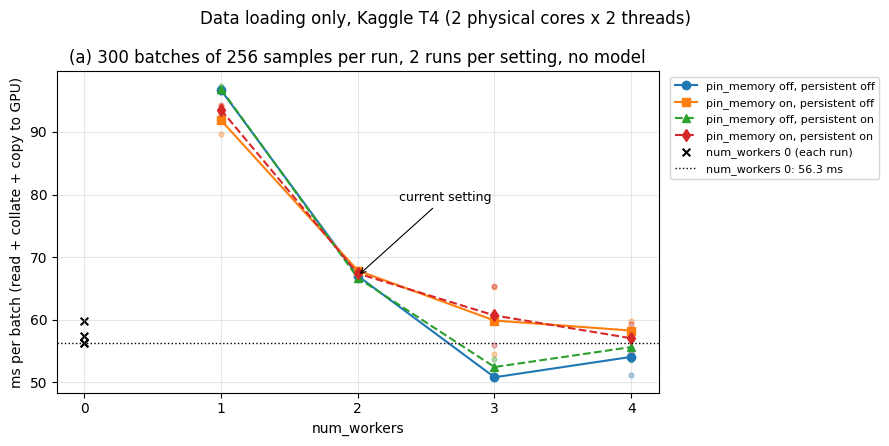

Hình: thời gian lấy một lô 256 mẫu khi chỉ lặp bộ nạp, không có mô hình (gồm cắt mẫu, ghép lô, chép sang GPU). Tổ hợp nhanh nhất ở mỗi mức num_workers 0-4: 56.3, 91.9, 66.7, 50.8, 54.1 ms/lô; cách đang dùng (2 tiến trình, không pin, không persistent) 67.0 ms/lô. Cùng một num_workers, các tổ hợp pin_memory/persistent_workers chênh nhau tối đa 9.9 ms, còn hai lần đo cùng một tổ hợp chênh tối đa 10.6 ms. Máy có 2 lõi thật x 2 luồng: tiến trình đọc phụ tranh CPU với tiến trình chính nên thêm tiến trình không làm nhanh tương ứng.


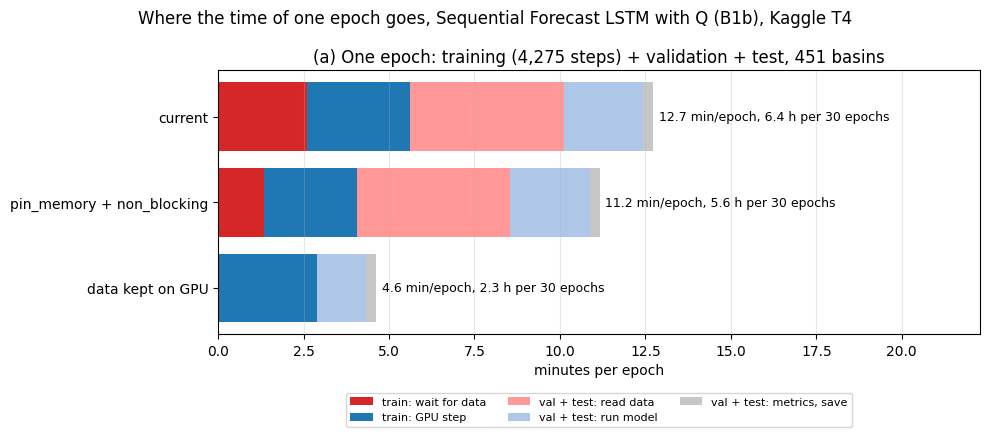

Hình: thời gian một epoch theo giao thức từ B0 (huấn luyện, rồi validation và chấm test trên 451 lưu vực), ngoại suy từ số đo Phần 6-8, chưa tính chi phí một lần ở epoch đầu (dựng dataset validation, test). Màu đỏ đậm là lúc GPU chờ dữ liệu khi huấn luyện, hồng là đọc dữ liệu khi chấm điểm: cách hiện tại 12.7 phút/epoch, trong đó 56% là chờ hoặc đọc dữ liệu. Bật pin_memory + non_blocking còn 11.2 phút; để sẵn dữ liệu trên GPU (lô lấy ngay trên GPU, trùng từng giá trị với bộ nạp thư viện) còn 4.6 phút, phần đọc dữ liệu gần như mất hẳn (thời gian lấy lô trên GPU gộp vào cột tính).


cách,huấn luyện (phút/epoch),validation + test (phút/epoch),tổng (phút/epoch),một lần chạy (giờ),tiết kiệm (phút/lần),tiết kiệm (%),luật >= 5%
current,5.63,7.11,12.74,6.45,0.00,0.00,-
pin_memory + non_blocking,4.05,7.11,11.16,5.67,47.29,12.21,ĐẠT
data kept on GPU,2.88,1.75,4.63,2.40,243.17,62.80,ĐẠT


tệp,KB,sha256
Figures/S0_DataLoader_EpochBreakdown.png,81.50,a968e4d68aa8...
Figures/S0_DataLoader_LoaderOnly.png,115.90,5b30b4d7aa27...
S0_B1b_SeqLSTM_Q_seed111.yml,3.50,0cbf20d4ae8b...
S0_EpochBreakdown.csv,0.40,f7c52c8ecbf3...
S0_GPUStore_Train.csv,0.30,51d52e4245c1...
S0_LoaderOnly_FullEpoch.csv,0.30,62744a345330...
S0_LoaderOnly_Runs.csv,3.30,2cf8325034c6...
S0_LoaderOnly_Summary.csv,2.20,edc0df7ba419...
S0_Summary.csv,0.50,34ba4ace5119...
S0_TrainStep_Runs.csv,0.70,b54a8b4e832d...


Thư mục khác còn trong /kaggle/working: ['__notebook__.ipynb']
=> Xong notebook.


In [9]:
# %% Phần 9 - Hình, bảng tổng hợp, môi trường, danh mục tệp
# Hai hình (chữ tiếng Anh, chú thích tiếng Việt in ngay dưới): (1) chỉ bộ nạp, ms/lô theo num_workers (Phần 5);
# (2) một epoch theo giao thức từ B0 (huấn luyện + validation + chấm test mỗi epoch, 02_Pipeline.md Mục 5.1) chia theo thành
# phần, cho 3 cách: hiện tại, pin + non_blocking (Phần 6), dữ liệu sẵn trên GPU (Phần 8). Bảng tổng hợp ngoại suy một lần
# chạy 30 epoch và áp luật quyết định ghi trước (tiết kiệm từ 5% một lần chạy => sửa fork trước B0).
# Rồi ghi environment.json, chép config, xóa thư mục dữ liệu dựng ở Phần 3 và thư mục run (dựng lại được) để Output chỉ còn
# s0_output, ghi manifest.csv (mọi tệp kèm sha256).
import hashlib

import matplotlib.pyplot as plt

FIG_DIR = OUT_DIR / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
N_EVAL_PASSES = 2                        # validation + chấm test mỗi epoch
SAVE_RULE = 0.05                         # luật quyết định: tiết kiệm từ 5% một lần chạy


def caption(text):
    # Chú thích tiếng Việt in ngay dưới hình (chữ trong hình tiếng Anh).
    print(f"Hình: {text}")


def sha256(path):
    h = hashlib.sha256()
    with Path(path).open("rb") as fp:
        for chunk in iter(lambda: fp.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


# (1) Hình chỉ bộ nạp: điểm = từng lần đo, đường = trung vị, vạch ngang = đọc ở tiến trình chính
fig, ax = plt.subplots(figsize=(9, 4.5))
styles = {(False, False): ("o-", "C0"), (True, False): ("s-", "C1"), (False, True): ("^--", "C2"), (True, True): ("d--", "C3")}
for (pin, pers), (mk, col) in styles.items():
    g = grid[(grid["num_workers"] > 0) & (grid["pin_memory"] == pin) & (grid["persistent_workers"] == pers)]
    g = g.sort_values("num_workers")
    r = runs[(runs["num_workers"] > 0) & (runs["pin_memory"] == pin) & (runs["persistent_workers"] == pers)]
    ax.plot(g["num_workers"], g["ms_per_batch"], mk, color=col,
            label=f"pin_memory {'on' if pin else 'off'}, persistent {'on' if pers else 'off'}")
    ax.scatter(r["num_workers"], r["ms_per_batch"], s=12, color=col, alpha=0.35)
r0 = runs[runs["num_workers"] == 0]
ms0 = float(grid.loc[grid["num_workers"] == 0, "ms_per_batch"].min())
ax.scatter(r0["num_workers"], r0["ms_per_batch"], s=30, color="k", marker="x", label="num_workers 0 (each run)")
ax.axhline(ms0, color="k", ls=":", lw=1, label=f"num_workers 0: {ms0:.1f} ms")
now = grid[(grid["num_workers"] == N_WORKERS_NOW) & ~grid["pin_memory"] & ~grid["persistent_workers"]].iloc[0]
ax.annotate("current setting", xy=(N_WORKERS_NOW, now["ms_per_batch"]), xytext=(N_WORKERS_NOW + 0.3, now["ms_per_batch"] + 12),
            arrowprops=dict(arrowstyle="->", lw=0.8), fontsize=9)
ax.set(xlabel="num_workers", ylabel="ms per batch (read + collate + copy to GPU)", xticks=range(0, N_CPU + 1),
       title=f"(a) {N_BATCH_MEASURE} batches of {cfg.batch_size} samples per run, {N_REPEAT} runs per setting, no model")
ax.grid(alpha=0.3)
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)  # chú thích đặt ngoài vùng vẽ
fig.suptitle(f"Data loading only, Kaggle T4 ({cpu.get('Core(s) per socket', '?')} physical cores x "
             f"{cpu.get('Thread(s) per core', '?')} threads)")
fig.tight_layout()
fig.savefig(FIG_DIR / "S0_DataLoader_LoaderOnly.png", dpi=150, bbox_inches="tight")
plt.show()
per_nw = grid.groupby("num_workers")["ms_per_batch"].min()
combo_gap = grid[grid["num_workers"] > 0].groupby("num_workers")["ms_per_batch"].agg(lambda v: v.max() - v.min()).max()
rep_gap = runs.groupby(["num_workers", "pin_memory", "persistent_workers"])["ms_per_batch"].agg(
    lambda v: v.max() - v.min()).max()
caption(f"thời gian lấy một lô {cfg.batch_size} mẫu khi chỉ lặp bộ nạp, không có mô hình (gồm cắt mẫu, ghép lô, chép sang "
        f"GPU). Tổ hợp nhanh nhất ở mỗi mức num_workers 0-{N_CPU}: " + ", ".join(f"{v:.1f}" for v in per_nw) +
        f" ms/lô; cách đang dùng (2 tiến trình, không pin, không persistent) {now['ms_per_batch']:.1f} ms/lô. Cùng một "
        f"num_workers, các tổ hợp pin_memory/persistent_workers chênh nhau tối đa {combo_gap:.1f} ms, còn hai lần đo cùng "
        f"một tổ hợp chênh tối đa {rep_gap:.1f} ms. Máy có {cpu.get('Core(s) per socket', '?')} lõi thật x "
        f"{cpu.get('Thread(s) per core', '?')} luồng: tiến trình đọc phụ tranh CPU với tiến trình chính nên thêm tiến trình "
        "không làm nhanh tương ứng.")

# (2) Một epoch theo thành phần (phút), 3 cách
steps = len(loader)
row = lambda name: sum6.set_index("cấu hình").loc[name]
val2 = val.iloc[1]
metrics_min = (val2["xarray + chỉ số (s)"] + val2["ghi kết quả (s)"]) / 60
parts = ["train: wait for data", "train: GPU step", "val + test: read data", "val + test: run model",
         "val + test: metrics, save"]
epoch = pd.DataFrame({
    "current": [row("hiện tại")["chờ dữ liệu (ms)"] * steps / 6e4, row("hiện tại")["tính (ms)"] * steps / 6e4,
                N_EVAL_PASSES * TIMING["val_data_s"] / 60, N_EVAL_PASSES * TIMING["val_model_s"] / 60,
                N_EVAL_PASSES * metrics_min],
    "pin_memory + non_blocking": [row("tốt nhất + pin + non_blocking")["chờ dữ liệu (ms)"] * steps / 6e4,
                                  row("tốt nhất + pin + non_blocking")["tính (ms)"] * steps / 6e4,
                                  N_EVAL_PASSES * TIMING["val_data_s"] / 60, N_EVAL_PASSES * TIMING["val_model_s"] / 60,
                                  N_EVAL_PASSES * metrics_min],
    "data kept on GPU": [0.0, TIMING["train_ms_gpu_store"] * steps / 6e4, 0.0,
                         N_EVAL_PASSES * TIMING["val_gpu_256_s"] / 60, N_EVAL_PASSES * metrics_min]}, index=parts).T
fig, ax = plt.subplots(figsize=(10, 4.6))
left = np.zeros(len(epoch))
colors = ["#d62728", "#1f77b4", "#ff9896", "#aec7e8", "#c7c7c7"]
for p, c in zip(parts, colors):
    ax.barh(epoch.index, epoch[p], left=left, color=c, label=p)
    left += epoch[p].to_numpy()
for y, tot in enumerate(left):
    ax.text(tot + 0.15, y, f"{tot:.1f} min/epoch, {tot * cfg.epochs / 60:.1f} h per {cfg.epochs} epochs", va="center",
            fontsize=9)
ax.invert_yaxis()
ax.set(xlabel="minutes per epoch", xlim=(0, left.max() * 1.75),
       title=f"(a) One epoch: training ({steps:,} steps) + validation + test, {len(validator.cached_datasets)} basins")
ax.grid(axis="x", alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3, fontsize=8)  # chú thích đặt dưới vùng vẽ
fig.suptitle("Where the time of one epoch goes, Sequential Forecast LSTM with Q (B1b), Kaggle T4")
fig.tight_layout()
fig.savefig(FIG_DIR / "S0_DataLoader_EpochBreakdown.png", dpi=150, bbox_inches="tight")
plt.show()
tot = dict(zip(epoch.index, left))
share = (epoch.loc["current", parts[0]] + epoch.loc["current", parts[2]]) / tot["current"]
caption(f"thời gian một epoch theo giao thức từ B0 (huấn luyện, rồi validation và chấm test trên {len(validator.cached_datasets)} "
        f"lưu vực), ngoại suy từ số đo Phần 6-8, chưa tính chi phí một lần ở epoch đầu (dựng dataset validation, test). Màu "
        f"đỏ đậm là lúc GPU chờ dữ liệu khi huấn luyện, hồng là đọc dữ liệu khi chấm điểm: cách hiện tại "
        f"{tot['current']:.1f} phút/epoch, trong đó {share:.0%} là chờ hoặc đọc dữ liệu. Bật pin_memory + non_blocking còn "
        f"{tot['pin_memory + non_blocking']:.1f} phút; để sẵn dữ liệu trên GPU (lô lấy ngay trên GPU, trùng từng giá trị "
        f"với bộ nạp thư viện) còn {tot['data kept on GPU']:.1f} phút, phần đọc dữ liệu gần như mất hẳn (thời gian lấy lô "
        f"trên GPU gộp vào cột tính).")

# (3) Bảng tổng hợp: một lần chạy 30 epoch, luật quyết định
one_time_min = (TIMING["init_training"] + N_EVAL_PASSES * (TIMING["val_pass1_min"] - TIMING["val_pass2_min"]) * 60) / 60
summary = pd.DataFrame({"cách": epoch.index, "huấn luyện (phút/epoch)": epoch[parts[:2]].sum(axis=1).to_numpy(),
                        "validation + test (phút/epoch)": epoch[parts[2:]].sum(axis=1).to_numpy(),
                        "tổng (phút/epoch)": left})
summary["một lần chạy (giờ)"] = (summary["tổng (phút/epoch)"] * cfg.epochs + one_time_min) / 60
base_h = summary["một lần chạy (giờ)"].iloc[0]
summary["tiết kiệm (phút/lần)"] = (base_h - summary["một lần chạy (giờ)"]) * 60
summary["tiết kiệm (%)"] = (1 - summary["một lần chạy (giờ)"] / base_h) * 100
summary["luật >= 5%"] = ["-"] + ["ĐẠT" if v >= SAVE_RULE * 100 else "KHÔNG" for v in summary["tiết kiệm (%)"].iloc[1:]]
show(f"Một lần chạy {cfg.epochs} epoch (gồm {one_time_min:.1f} phút chi phí một lần: dựng trainer, dựng dataset "
     f"validation và test ở epoch đầu)", summary.round(2))
summary.to_csv(OUT_DIR / "S0_Summary.csv", index=False)
epoch.to_csv(OUT_DIR / "S0_EpochBreakdown.csv")

# (4) environment.json, config; xóa dữ liệu dựng lại được
nh_commit = json.loads(md.distribution("neuralhydrology").read_text("direct_url.json") or "{}").get(
    "vcs_info", {}).get("commit_id", "không rõ")
shutil.copy(CFG_PATH, OUT_DIR / CFG_PATH.name)
env = {"notebook": "02_0_DataLoader_Benchmark", "input": str(LAMAH_DIR.parent), "neuralhydrology_commit": nh_commit,
       "neuralhydrology_commit_expected": NH_COMMIT, "environment": {k: str(v) for k, v in ENV.items()}, "lscpu": cpu,
       "libs": {lib: md.version(lib) for lib in ["neuralhydrology"] + CHECK_LIBS},
       "config": CFG_PATH.name, "config_sha256": sha256(CFG_PATH), "loader_seed": LOADER_SEED,
       "timing": {k: float(v) for k, v in TIMING.items()}}
(OUT_DIR / "environment.json").write_text(json.dumps(env, ensure_ascii=False, indent=2), encoding="utf-8")
for d in (Q_DIR, RUNS_DIR, CFG_PATH.parent):
    shutil.rmtree(d, ignore_errors=True)    # liên kết tới Input chỉ bị gỡ, không xóa bản gốc

# (5) manifest.csv: mọi tệp trong s0_output
logging.shutdown()
files = sorted(p for p in OUT_DIR.rglob("*") if p.is_file() and p.name != "manifest.csv")
manifest = pd.DataFrame([{"tệp": p.relative_to(OUT_DIR).as_posix(), "KB": round(p.stat().st_size / 1024, 1),
                          "sha256": sha256(p)} for p in files])
manifest.to_csv(OUT_DIR / "manifest.csv", index=False)
show(f"Output s0_output ({len(manifest)} tệp, manifest.csv)", manifest.assign(sha256=manifest["sha256"].str[:12] + "..."))
left_dirs = [p.name for p in WORK_DIR.iterdir() if p.name != OUT_DIR.name]
print(f"Thư mục khác còn trong {WORK_DIR}: {left_dirs or 'không'}")
print("=> Xong notebook.")
